In [6]:

import os
import io
import zipfile
import shutil
import random
import numpy as np
import pandas as pd
import torch
from google.colab import files

# =====================================
# 1. Configuration
# =====================================
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_PATH = "/content/jigsaw-toxic-comment-classification-challenge.zip"

print("GPU:", torch.cuda.get_device_name(0)
      if torch.cuda.is_available() else "CPU")

# =====================================
# 2. Check ZIP File
# =====================================
if os.path.exists(DATA_PATH):
    print("Current file size:", os.path.getsize(DATA_PATH), "bytes")
    with open(DATA_PATH, "rb") as f:
        print("File header:", repr(f.read(20)))

# Find another valid copy if necessary
if not zipfile.is_zipfile(DATA_PATH):

    print("\nExisting file is not a valid ZIP.")

    candidates = [
        os.path.join("/content", name)
        for name in os.listdir("/content")
        if name.lower().endswith(".zip")
        and os.path.join("/content", name) != DATA_PATH
    ]

    valid_files = [
        p for p in candidates if zipfile.is_zipfile(p)
    ]

    if valid_files:
        shutil.copyfile(valid_files[0], DATA_PATH)
        print("Recovered from:", valid_files[0])

    else:
        print("\nPlease select the original Jigsaw ZIP file.")
        uploaded = files.upload()

        valid_uploads = [
            name for name, content in uploaded.items()
            if zipfile.is_zipfile(io.BytesIO(content))
        ]

        if not valid_uploads:
            raise ValueError("Uploaded file is not a valid ZIP.")

        with open(DATA_PATH, "wb") as f:
            f.write(uploaded[valid_uploads[0]])

print("\nZIP verification:", zipfile.is_zipfile(DATA_PATH))

# =====================================
# 3. Load Nested CSV Files
# =====================================
with zipfile.ZipFile(DATA_PATH, "r") as outer:

    print("\nArchive contents:")
    print(outer.namelist())

    def load_csv(filename):
        nested = filename + ".zip"

        if nested in outer.namelist():
            data = outer.read(nested)

            with zipfile.ZipFile(io.BytesIO(data)) as inner:
                return pd.read_csv(inner.open(filename))

        elif filename in outer.namelist():
            return pd.read_csv(outer.open(filename))

        else:
            raise FileNotFoundError(filename)

    train_df = load_csv("train.csv")
    test_df = load_csv("test.csv")
    test_labels_df = load_csv("test_labels.csv")

# =====================================
# 4. Define Labels
# =====================================
LABELS = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

# =====================================
# 5. Prepare Valid Test Dataset
# =====================================
valid_mask = (test_labels_df[LABELS] != -1).all(axis=1)

official_test_df = test_df.loc[valid_mask].copy()

official_test_df[LABELS] = (
    test_labels_df.loc[valid_mask, LABELS].to_numpy()
)

# =====================================
# 6. Display Results
# =====================================
print("\n========== DATASET VERIFIED ==========")
print("Training:", train_df.shape)
print("Test:", test_df.shape)
print("Labeled test:", official_test_df.shape)

print("\nClass distribution:")
print(train_df[LABELS].sum())

print("\nMissing values:")
print(train_df.isnull().sum())

display(train_df.head())

print("\nSUCCESS: Dataset loaded!")


GPU: Tesla T4
Current file size: 50331648 bytes
File header: b'PK\x03\x04-\x00\x00\x00\x08\x00\x14 \x8bO\xde\x06\xfe\xb8\xff\xff'

Existing file is not a valid ZIP.

Please select the original Jigsaw ZIP file.


Saving jigsaw-toxic-comment-classification-challenge.zip to jigsaw-toxic-comment-classification-challenge (1).zip

ZIP verification: True

Archive contents:
['sample_submission.csv.zip', 'test.csv.zip', 'test_labels.csv.zip', 'train.csv.zip']

========== DATASET VERIFIED ==========
Training: (159571, 8)
Test: (153164, 2)
Labeled test: (63978, 8)

Class distribution:
toxic            15294
severe_toxic      1595
obscene           8449
threat             478
insult            7877
identity_hate     1405
dtype: int64

Missing values:
id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0



SUCCESS: Dataset loaded!


========== DATASET STATISTICS ==========
Total training comments: 159571
Total test comments: 153164
Valid labeled test comments: 63978

========== CLASS DISTRIBUTION ==========


,Count,Percentage (%)
toxic,15294,9.58
severe_toxic,1595,1.00
obscene,8449,5.29
threat,478,0.30
insult,7877,4.94
identity_hate,1405,0.88



========== TOXIC VS NON-TOXIC ==========
Non-toxic comments: 143346
Comments with >=1 toxic label: 16225


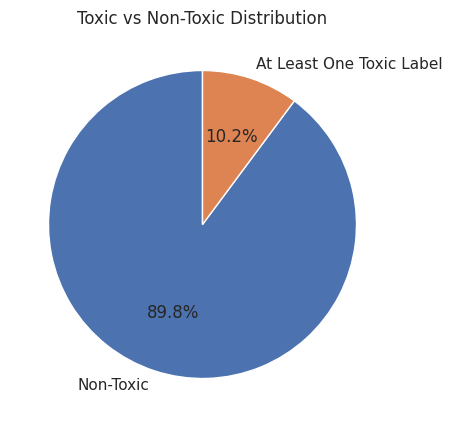

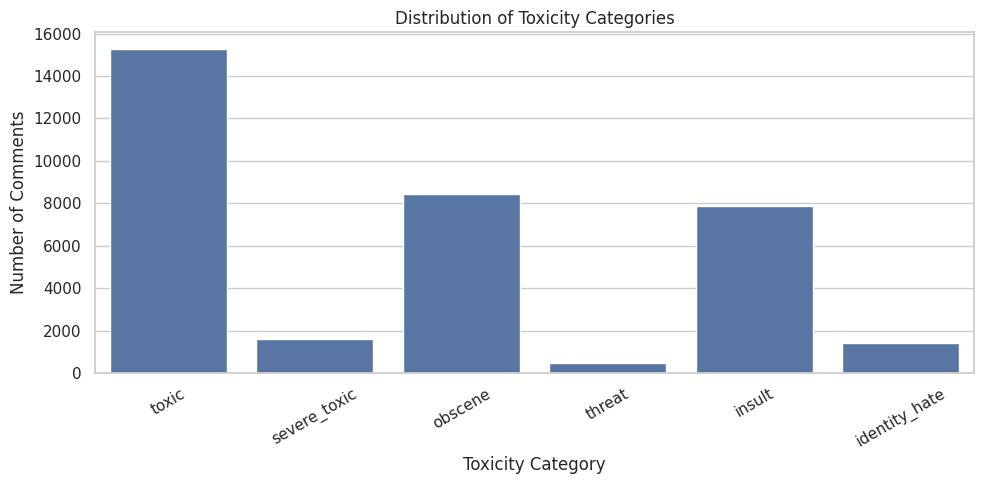

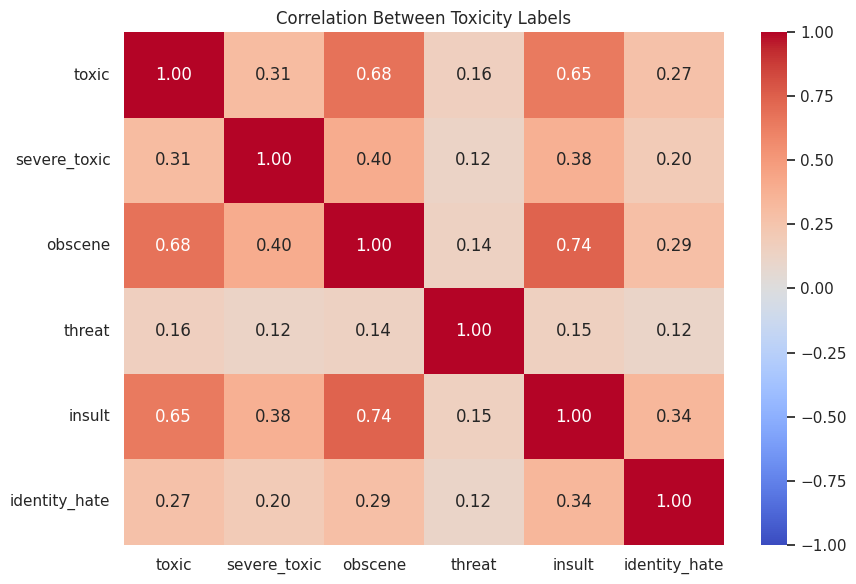

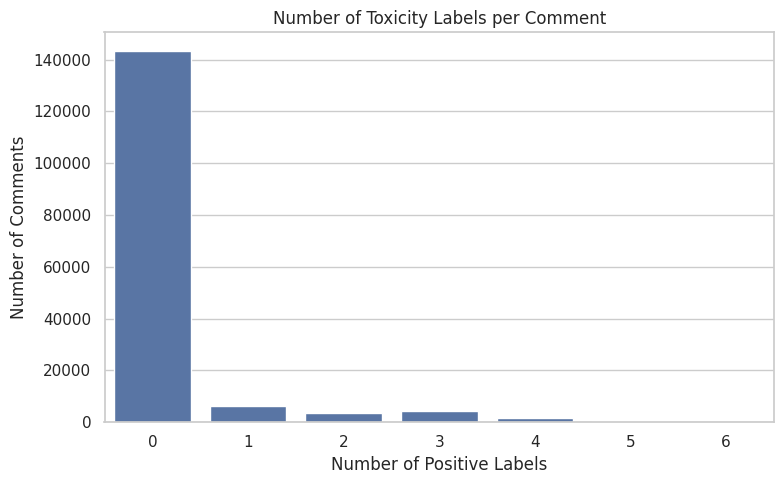


========== COMMENT LENGTH ==========
count    159571.000000
mean         67.273527
std          99.230702
min           1.000000
25%          17.000000
50%          36.000000
75%          75.000000
max        1411.000000
Name: comment_text, dtype: float64


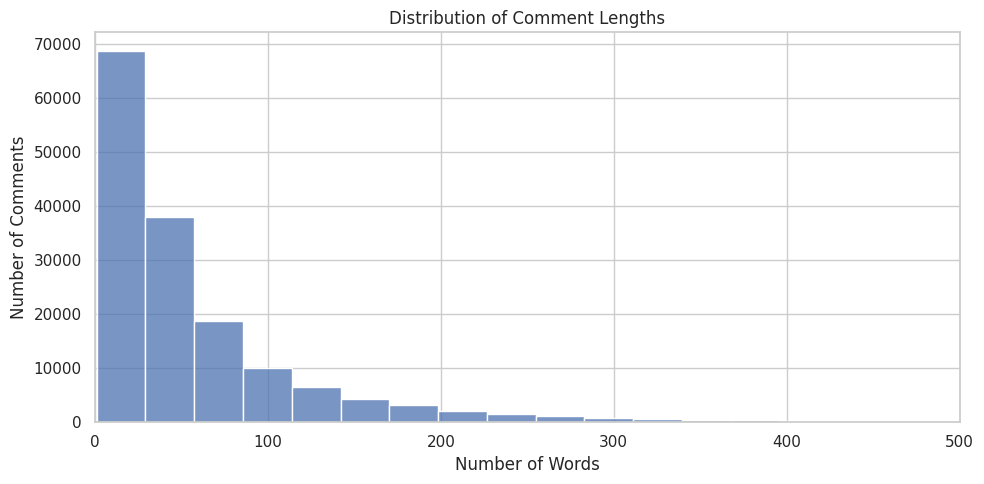


========== DATA QUALITY ==========
Duplicate comment texts: 0
Missing comment texts: 0

EDA COMPLETED SUCCESSFULLY!


In [7]:

# ==========================================
# CELL 2: EXPLORATORY DATA ANALYSIS
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

assert "train_df" in globals(), "Run Cell 1 first."

# ==========================================
# 1. Basic Dataset Statistics
# ==========================================
print("========== DATASET STATISTICS ==========")

print("Total training comments:", len(train_df))
print("Total test comments:", len(test_df))
print("Valid labeled test comments:", len(official_test_df))

# ==========================================
# 2. Class Distribution
# ==========================================
label_counts = train_df[LABELS].sum()

label_percentages = (
    label_counts / len(train_df) * 100
).round(2)

class_distribution = pd.DataFrame({
    "Count": label_counts.astype(int),
    "Percentage (%)": label_percentages
})

print("\n========== CLASS DISTRIBUTION ==========")
display(class_distribution)

# ==========================================
# 3. Toxic vs Non-Toxic Comments
# ==========================================
label_count = train_df[LABELS].sum(axis=1)

non_toxic = (label_count == 0).sum()
toxic = (label_count > 0).sum()

print("\n========== TOXIC VS NON-TOXIC ==========")
print("Non-toxic comments:", non_toxic)
print("Comments with >=1 toxic label:", toxic)

plt.figure(figsize=(7, 5))
plt.pie(
    [non_toxic, toxic],
    labels=["Non-Toxic", "At Least One Toxic Label"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Toxic vs Non-Toxic Distribution")
plt.show()

# ==========================================
# 4. Individual Class Distribution
# ==========================================
plt.figure(figsize=(10, 5))

sns.barplot(
    x=label_counts.index,
    y=label_counts.values
)

plt.title("Distribution of Toxicity Categories")
plt.xlabel("Toxicity Category")
plt.ylabel("Number of Comments")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# ==========================================
# 5. Label Correlation
# ==========================================
plt.figure(figsize=(9, 6))

sns.heatmap(
    train_df[LABELS].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Toxicity Labels")
plt.tight_layout()
plt.show()

# ==========================================
# 6. Multiple Labels Per Comment
# ==========================================
plt.figure(figsize=(8, 5))

sns.countplot(x=label_count)

plt.title("Number of Toxicity Labels per Comment")
plt.xlabel("Number of Positive Labels")
plt.ylabel("Number of Comments")
plt.tight_layout()
plt.show()

# ==========================================
# 7. Comment Length Analysis
# ==========================================
comment_lengths = (
    train_df["comment_text"]
    .fillna("")
    .str.split()
    .str.len()
)

print("\n========== COMMENT LENGTH ==========")
print(comment_lengths.describe())

plt.figure(figsize=(10, 5))

sns.histplot(
    comment_lengths,
    bins=50
)

plt.xlim(0, 500)
plt.title("Distribution of Comment Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Comments")
plt.tight_layout()
plt.show()

# ==========================================
# 8. Check Duplicate and Missing Data
# ==========================================
print("\n========== DATA QUALITY ==========")

print(
    "Duplicate comment texts:",
    train_df["comment_text"].duplicated().sum()
)

print(
    "Missing comment texts:",
    train_df["comment_text"].isna().sum()
)

print("\nEDA COMPLETED SUCCESSFULLY!")


In [8]:

# ==========================================
# CELL 3: PREPROCESSING AND DATA SPLITTING
# ==========================================

%pip -q install iterative-stratification

import os
import json
import random
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

# ==========================================
# 1. Reproducibility
# ==========================================
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

OUTPUT_DIR = "/content/jigsaw_research"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ==========================================
# 2. Validate Input Dataset
# ==========================================
assert "train_df" in globals(), "Run Cell 1 first."
assert "official_test_df" in globals(), "Run Cell 1 first."

LABELS = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

assert not train_df["comment_text"].isna().any()
assert train_df[LABELS].notna().all().all()

# Preserve original text for reproducibility.
# TF-IDF models will handle lowercasing internally.
# Transformer models will use the original text.

data = train_df[
    ["id", "comment_text"] + LABELS
].copy()

data["comment_text"] = (
    data["comment_text"].astype(str)
)

# ==========================================
# 3. Multi-Label Stratified Split
# ==========================================
splitter = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED
)

train_idx, val_idx = next(
    splitter.split(
        data["comment_text"],
        data[LABELS].values
    )
)

train_split = data.iloc[train_idx].copy().reset_index(drop=True)
val_split = data.iloc[val_idx].copy().reset_index(drop=True)

# ==========================================
# 4. Prepare Features and Target Labels
# ==========================================
X_train_text = train_split["comment_text"]
X_val_text = val_split["comment_text"]

y_train = train_split[LABELS].to_numpy(dtype=np.int32)
y_val = val_split[LABELS].to_numpy(dtype=np.int32)

X_test_text = official_test_df["comment_text"].fillna("").astype(str)
y_test = official_test_df[LABELS].to_numpy(dtype=np.int32)

# ==========================================
# 5. Verify Splitting
# ==========================================
print("========== DATA SPLIT ==========")

print("Training:", len(train_split))
print("Validation:", len(val_split))
print("Official labeled test:", len(official_test_df))

train_ids = set(train_split["id"])
val_ids = set(val_split["id"])

assert train_ids.isdisjoint(val_ids)
assert len(train_split) + len(val_split) == len(data)

print("\nNo training-validation ID overlap.")

# ==========================================
# 6. Compare Class Distribution
# ==========================================
distribution_check = pd.DataFrame({
    "Training (%)": train_split[LABELS].mean() * 100,
    "Validation (%)": val_split[LABELS].mean() * 100,
    "Official Test (%)": official_test_df[LABELS].mean() * 100
}).round(3)

print("\n========== LABEL DISTRIBUTION ==========")
display(distribution_check)

# ==========================================
# 7. Save Fixed Split for Reproducibility
# ==========================================
train_split.to_csv(
    f"{OUTPUT_DIR}/train_split.csv",
    index=False
)

val_split.to_csv(
    f"{OUTPUT_DIR}/validation_split.csv",
    index=False
)

config = {
    "seed": SEED,
    "train_size": len(train_split),
    "validation_size": len(val_split),
    "test_size": len(official_test_df),
    "labels": LABELS,
    "validation_fraction": 0.20,
    "split_method": "iterative multilabel stratification"
}

with open(f"{OUTPUT_DIR}/experiment_config.json", "w") as f:
    json.dump(config, f, indent=4)

print("\nSaved training split, validation split and experiment configuration.")
print("Data preparation completed successfully!")


========== DATA SPLIT ==========
Training: 127656
Validation: 31915
Official labeled test: 63978

No training-validation ID overlap.

========== LABEL DISTRIBUTION ==========


,Training (%),Validation (%),Official Test (%)
toxic,9.584,9.585,9.519
severe_toxic,1.000,1.000,0.574
obscene,5.295,5.295,5.769
threat,0.299,0.301,0.330
insult,4.937,4.935,5.357
identity_hate,0.880,0.880,1.113



Saved training split, validation split and experiment configuration.
Data preparation completed successfully!


In [9]:

# ==================================================
# CELL 4: TF-IDF + LOGISTIC REGRESSION BASELINE
# ==================================================

import os
import time
import joblib
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

from sklearn.metrics import (
    precision_recall_fscore_support,
    f1_score,
    roc_auc_score,
    average_precision_score,
    hamming_loss,
    accuracy_score
)

# ==================================================
# 1. Configuration
# ==================================================

SEED = 42
OUTPUT_DIR = "/content/jigsaw_research"
os.makedirs(OUTPUT_DIR, exist_ok=True)

MODEL_NAME = "LR_Word_TFIDF"

assert "train_split" in globals(), "Run Cell 3 first."
assert "val_split" in globals(), "Run Cell 3 first."

# ==================================================
# 2. Prepare Training and Validation Data
# ==================================================

X_train_text = train_split["comment_text"].fillna("")
X_val_text = val_split["comment_text"].fillna("")

y_train = train_split[LABELS].to_numpy()
y_val = val_split[LABELS].to_numpy()

print("Training samples:", len(X_train_text))
print("Validation samples:", len(X_val_text))

# ==================================================
# 3. TF-IDF Feature Extraction
# ==================================================

print("\nExtracting TF-IDF features...")

tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.98,
    max_features=100000,
    sublinear_tf=True,
    dtype=np.float32
)

start_time = time.time()

X_train_tfidf = tfidf.fit_transform(X_train_text)

# Never fit TF-IDF on validation or test data
X_val_tfidf = tfidf.transform(X_val_text)

print("Training feature shape:", X_train_tfidf.shape)
print("Validation feature shape:", X_val_tfidf.shape)

# ==================================================
# 4. Train Logistic Regression
# ==================================================

print("\nTraining Logistic Regression...")

lr_model = OneVsRestClassifier(
    LogisticRegression(
        C=1.0,
        max_iter=1000,
        solver="liblinear",
        random_state=SEED
    ),
    n_jobs=1
)

lr_model.fit(X_train_tfidf, y_train)

training_time = time.time() - start_time

print("Training completed!")
print(f"Total processing time: {training_time:.2f} seconds")

# ==================================================
# 5. Predict Validation Probabilities
# ==================================================

y_prob = lr_model.predict_proba(X_val_tfidf)

# Fixed baseline threshold
THRESHOLD = 0.50

y_pred = (y_prob >= THRESHOLD).astype(int)

# ==================================================
# 6. Evaluate Each Toxicity Category
# ==================================================

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_val,
        y_pred,
        average=None,
        zero_division=0
    )
)

per_class_results = []

for i, label in enumerate(LABELS):

    auc = roc_auc_score(
        y_val[:, i],
        y_prob[:, i]
    )

    ap = average_precision_score(
        y_val[:, i],
        y_prob[:, i]
    )

    per_class_results.append({
        "Label": label,
        "Precision": precision[i],
        "Recall": recall[i],
        "F1": f1[i],
        "ROC_AUC": auc,
        "AP": ap,
        "Support": support[i]
    })

per_class_df = pd.DataFrame(per_class_results)

print("\n========== PER-CLASS PERFORMANCE ==========")

display(per_class_df.round(4))

# ==================================================
# 7. Overall Evaluation Metrics
# ==================================================

macro_f1 = f1_score(
    y_val, y_pred,
    average="macro",
    zero_division=0
)

micro_f1 = f1_score(
    y_val, y_pred,
    average="micro",
    zero_division=0
)

weighted_f1 = f1_score(
    y_val, y_pred,
    average="weighted",
    zero_division=0
)

macro_auc = roc_auc_score(
    y_val, y_prob,
    average="macro"
)

macro_ap = average_precision_score(
    y_val, y_prob,
    average="macro"
)

subset_accuracy = accuracy_score(y_val, y_pred)

loss = hamming_loss(y_val, y_pred)

print("\n========== OVERALL MODEL PERFORMANCE ==========")

print(f"Macro F1        : {macro_f1:.4f}")
print(f"Micro F1        : {micro_f1:.4f}")
print(f"Weighted F1     : {weighted_f1:.4f}")
print(f"Macro ROC-AUC   : {macro_auc:.4f}")
print(f"Macro AP        : {macro_ap:.4f}")
print(f"Subset Accuracy : {subset_accuracy:.4f}")
print(f"Hamming Loss    : {loss:.4f}")

# ==================================================
# 8. Save Model and Validation Predictions
# ==================================================

joblib.dump(
    tfidf,
    f"{OUTPUT_DIR}/tfidf_word_vectorizer.joblib"
)

joblib.dump(
    lr_model,
    f"{OUTPUT_DIR}/logistic_regression_baseline.joblib"
)

np.savez_compressed(
    f"{OUTPUT_DIR}/LR_Word_TFIDF_validation.npz",
    y_true=y_val,
    y_prob=y_prob,
    y_pred=y_pred
)

per_class_df.to_csv(
    f"{OUTPUT_DIR}/LR_Word_TFIDF_per_class.csv",
    index=False
)

# ==================================================
# 9. Save Result for Future Model Comparisons
# ==================================================

result = pd.DataFrame([{
    "Model": MODEL_NAME,
    "Macro_F1": macro_f1,
    "Micro_F1": micro_f1,
    "Weighted_F1": weighted_f1,
    "Macro_ROC_AUC": macro_auc,
    "Macro_AP": macro_ap,
    "Subset_Accuracy": subset_accuracy,
    "Hamming_Loss": loss,
    "Threshold": THRESHOLD
}])

result.to_csv(
    f"{OUTPUT_DIR}/LR_Word_TFIDF_results.csv",
    index=False
)

print("\nBaseline model and results saved successfully!")
print("CELL 4 COMPLETED!")


Training samples: 127656
Validation samples: 31915

Extracting TF-IDF features...
Training feature shape: (127656, 100000)
Validation feature shape: (31915, 100000)

Training Logistic Regression...
Training completed!
Total processing time: 59.59 seconds

========== PER-CLASS PERFORMANCE ==========


,Label,Precision,Recall,F1,ROC_AUC,AP,Support
0,toxic,0.9322,0.5665,0.7048,0.9729,0.8642,3059
1,severe_toxic,0.5915,0.2633,0.3644,0.9864,0.4552,319
2,obscene,0.9318,0.6059,0.7343,0.9821,0.8744,1690
3,threat,0.9000,0.0938,0.1698,0.9832,0.3825,96
4,insult,0.8377,0.5079,0.6324,0.9754,0.7659,1575
5,identity_hate,0.6154,0.1139,0.1922,0.9700,0.3814,281



========== OVERALL MODEL PERFORMANCE ==========
Macro F1        : 0.4663
Micro F1        : 0.6612
Weighted F1     : 0.6523
Macro ROC-AUC   : 0.9783
Macro AP        : 0.6206
Subset Accuracy : 0.9188
Hamming Loss    : 0.0197

Baseline model and results saved successfully!
CELL 4 COMPLETED!


In [10]:

# ==================================================
# CELL 5: TF-IDF + MULTINOMIAL NAIVE BAYES
# ==================================================

import os
import time
import joblib
import numpy as np
import pandas as pd

from sklearn.naive_bayes import MultinomialNB
from sklearn.multiclass import OneVsRestClassifier

from sklearn.metrics import (
    precision_recall_fscore_support,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    hamming_loss
)

# ==================================================
# 1. Configuration
# ==================================================

SEED = 42
OUTPUT_DIR = "/content/jigsaw_research"
MODEL_NAME = "NB_Word_TFIDF"
THRESHOLD = 0.50

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ==================================================
# 2. Reuse TF-IDF Features from Cell 4
# ==================================================

if "X_train_tfidf" not in globals():

    tfidf = joblib.load(
        f"{OUTPUT_DIR}/tfidf_word_vectorizer.joblib"
    )

    X_train_tfidf = tfidf.transform(
        train_split["comment_text"].fillna("")
    )

    X_val_tfidf = tfidf.transform(
        val_split["comment_text"].fillna("")
    )

y_train = train_split[LABELS].to_numpy()
y_val = val_split[LABELS].to_numpy()

print("Training:", X_train_tfidf.shape)
print("Validation:", X_val_tfidf.shape)

# ==================================================
# 3. Train Naive Bayes
# ==================================================

print("\nTraining Multinomial Naive Bayes...")

start_time = time.time()

nb_model = OneVsRestClassifier(
    MultinomialNB(alpha=1.0),
    n_jobs=1
)

nb_model.fit(X_train_tfidf, y_train)

training_time = time.time() - start_time

print("Training completed!")
print(f"Model fitting time: {training_time:.2f} seconds")

# ==================================================
# 4. Predict Validation Probabilities
# ==================================================

y_prob_nb = nb_model.predict_proba(X_val_tfidf)

y_pred_nb = (
    y_prob_nb >= THRESHOLD
).astype(int)

# ==================================================
# 5. Per-Class Performance
# ==================================================

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_val,
        y_pred_nb,
        average=None,
        zero_division=0
    )
)

per_class_results = []

for i, label in enumerate(LABELS):

    auc = roc_auc_score(
        y_val[:, i],
        y_prob_nb[:, i]
    )

    ap = average_precision_score(
        y_val[:, i],
        y_prob_nb[:, i]
    )

    per_class_results.append({
        "Label": label,
        "Precision": precision[i],
        "Recall": recall[i],
        "F1": f1[i],
        "ROC_AUC": auc,
        "AP": ap,
        "Support": support[i]
    })

per_class_nb_df = pd.DataFrame(per_class_results)

print("\n========== PER-CLASS PERFORMANCE ==========")
display(per_class_nb_df.round(4))

# ==================================================
# 6. Overall Performance
# ==================================================

results_nb = {
    "Model": MODEL_NAME,
    "Macro_F1": f1_score(
        y_val, y_pred_nb,
        average="macro",
        zero_division=0
    ),
    "Micro_F1": f1_score(
        y_val, y_pred_nb,
        average="micro",
        zero_division=0
    ),
    "Weighted_F1": f1_score(
        y_val, y_pred_nb,
        average="weighted",
        zero_division=0
    ),
    "Macro_ROC_AUC": roc_auc_score(
        y_val, y_prob_nb,
        average="macro"
    ),
    "Macro_AP": average_precision_score(
        y_val, y_prob_nb,
        average="macro"
    ),
    "Subset_Accuracy": accuracy_score(
        y_val, y_pred_nb
    ),
    "Hamming_Loss": hamming_loss(
        y_val, y_pred_nb
    ),
    "Threshold": THRESHOLD
}

print("\n========== OVERALL MODEL PERFORMANCE ==========")

for metric, value in results_nb.items():
    if metric != "Model":
        print(f"{metric:20s}: {value:.4f}")

# ==================================================
# 7. Save Model and Predictions
# ==================================================

joblib.dump(
    nb_model,
    f"{OUTPUT_DIR}/naive_bayes_baseline.joblib"
)

np.savez_compressed(
    f"{OUTPUT_DIR}/NB_Word_TFIDF_validation.npz",
    y_true=y_val,
    y_prob=y_prob_nb,
    y_pred=y_pred_nb
)

per_class_nb_df.to_csv(
    f"{OUTPUT_DIR}/NB_Word_TFIDF_per_class.csv",
    index=False
)

pd.DataFrame([results_nb]).to_csv(
    f"{OUTPUT_DIR}/NB_Word_TFIDF_results.csv",
    index=False
)

# ==================================================
# 8. Compare With Logistic Regression
# ==================================================

lr_results = pd.read_csv(
    f"{OUTPUT_DIR}/LR_Word_TFIDF_results.csv"
)

comparison_path = (
    f"{OUTPUT_DIR}/traditional_ml_comparison.csv"
)

if os.path.exists(comparison_path):
    comparison = pd.read_csv(comparison_path)
else:
    comparison = lr_results.copy()

comparison = pd.concat(
    [comparison, pd.DataFrame([results_nb])],
    ignore_index=True
)

comparison = comparison.drop_duplicates(
    subset=["Model"],
    keep="last"
)

comparison = comparison.sort_values(
    by="Macro_F1",
    ascending=False
).reset_index(drop=True)

comparison.to_csv(
    comparison_path,
    index=False
)

print("\n========== MODEL COMPARISON ==========")

display(
    comparison[
        [
            "Model",
            "Macro_F1",
            "Micro_F1",
            "Macro_ROC_AUC",
            "Macro_AP"
        ]
    ].round(4)
)

print("\nCELL 5 COMPLETED SUCCESSFULLY!")


Training: (127656, 100000)
Validation: (31915, 100000)

Training Multinomial Naive Bayes...
Training completed!
Model fitting time: 2.00 seconds

========== PER-CLASS PERFORMANCE ==========


,Label,Precision,Recall,F1,ROC_AUC,AP,Support
0,toxic,0.9556,0.3942,0.5582,0.9358,0.7723,3059
1,severe_toxic,0.6364,0.0219,0.0424,0.9270,0.3283,319
2,obscene,0.9590,0.3598,0.5232,0.9268,0.7163,1690
3,threat,0.0000,0.0000,0.0000,0.8039,0.0499,96
4,insult,0.8839,0.2756,0.4201,0.9235,0.6272,1575
5,identity_hate,0.0000,0.0000,0.0000,0.8476,0.1509,281



========== OVERALL MODEL PERFORMANCE ==========
Macro_F1            : 0.2573
Micro_F1            : 0.4788
Weighted_F1         : 0.4654
Macro_ROC_AUC       : 0.8941
Macro_AP            : 0.4408
Subset_Accuracy     : 0.9071
Hamming_Loss        : 0.0256
Threshold           : 0.5000

========== MODEL COMPARISON ==========


,Model,Macro_F1,Micro_F1,Macro_ROC_AUC,Macro_AP
0,LR_Word_TFIDF,0.4663,0.6612,0.9783,0.6206
1,NB_Word_TFIDF,0.2573,0.4788,0.8941,0.4408



CELL 5 COMPLETED SUCCESSFULLY!


In [11]:

# ==================================================
# CELL 6: TF-IDF + LINEAR SVM BASELINE
# ==================================================

import os
import time
import joblib
import numpy as np
import pandas as pd

from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsRestClassifier

from sklearn.metrics import (
    precision_recall_fscore_support,
    f1_score,
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    hamming_loss
)

# ==================================================
# 1. Configuration
# ==================================================

SEED = 42
OUTPUT_DIR = "/content/jigsaw_research"
MODEL_NAME = "SVM_Word_TFIDF"

os.makedirs(OUTPUT_DIR, exist_ok=True)

assert "train_split" in globals(), "Run Cell 3 first."
assert "val_split" in globals(), "Run Cell 3 first."

# ==================================================
# 2. Reuse TF-IDF Features
# ==================================================

if (
    "X_train_tfidf" not in globals()
    or "X_val_tfidf" not in globals()
):

    tfidf = joblib.load(
        f"{OUTPUT_DIR}/tfidf_word_vectorizer.joblib"
    )

    X_train_tfidf = tfidf.transform(
        train_split["comment_text"].fillna("")
    )

    X_val_tfidf = tfidf.transform(
        val_split["comment_text"].fillna("")
    )

y_train = train_split[LABELS].to_numpy()
y_val = val_split[LABELS].to_numpy()

print("Training:", X_train_tfidf.shape)
print("Validation:", X_val_tfidf.shape)

# ==================================================
# 3. Train Linear SVM
# ==================================================

print("\nTraining Linear SVM...")

start_time = time.time()

svm_model = OneVsRestClassifier(
    LinearSVC(
        C=1.0,
        max_iter=5000,
        tol=1e-4,
        dual="auto",
        random_state=SEED
    ),
    n_jobs=1
)

svm_model.fit(X_train_tfidf, y_train)

training_time = time.time() - start_time

print("\nTraining completed!")
print(f"Training time: {training_time:.2f} seconds")

# ==================================================
# 4. Predict Validation Scores
# ==================================================

# LinearSVC outputs decision scores, not probabilities.

y_score_svm = svm_model.decision_function(
    X_val_tfidf
)

# Default Linear SVM decision boundary = 0
y_pred_svm = (y_score_svm > 0).astype(int)

# ==================================================
# 5. Per-Class Evaluation
# ==================================================

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_val,
        y_pred_svm,
        average=None,
        zero_division=0
    )
)

per_class_results = []

for i, label in enumerate(LABELS):

    auc = roc_auc_score(
        y_val[:, i],
        y_score_svm[:, i]
    )

    ap = average_precision_score(
        y_val[:, i],
        y_score_svm[:, i]
    )

    per_class_results.append({
        "Label": label,
        "Precision": precision[i],
        "Recall": recall[i],
        "F1": f1[i],
        "ROC_AUC": auc,
        "AP": ap,
        "Support": support[i]
    })

per_class_svm_df = pd.DataFrame(
    per_class_results
)

print("\n========== PER-CLASS PERFORMANCE ==========")

display(per_class_svm_df.round(4))

# ==================================================
# 6. Overall Evaluation
# ==================================================

results_svm = {
    "Model": MODEL_NAME,

    "Macro_F1": f1_score(
        y_val,
        y_pred_svm,
        average="macro",
        zero_division=0
    ),

    "Micro_F1": f1_score(
        y_val,
        y_pred_svm,
        average="micro",
        zero_division=0
    ),

    "Weighted_F1": f1_score(
        y_val,
        y_pred_svm,
        average="weighted",
        zero_division=0
    ),

    "Macro_ROC_AUC": roc_auc_score(
        y_val,
        y_score_svm,
        average="macro"
    ),

    "Macro_AP": average_precision_score(
        y_val,
        y_score_svm,
        average="macro"
    ),

    "Subset_Accuracy": accuracy_score(
        y_val,
        y_pred_svm
    ),

    "Hamming_Loss": hamming_loss(
        y_val,
        y_pred_svm
    ),

    "Threshold": 0.0
}

print("\n========== OVERALL MODEL PERFORMANCE ==========")

for metric, value in results_svm.items():
    if metric != "Model":
        print(f"{metric:20s}: {value:.4f}")

# ==================================================
# 7. Save Model and Predictions
# ==================================================

joblib.dump(
    svm_model,
    f"{OUTPUT_DIR}/linear_svm_baseline.joblib"
)

np.savez_compressed(
    f"{OUTPUT_DIR}/SVM_Word_TFIDF_validation.npz",
    y_true=y_val,
    y_score=y_score_svm,
    y_pred=y_pred_svm
)

per_class_svm_df.to_csv(
    f"{OUTPUT_DIR}/SVM_Word_TFIDF_per_class.csv",
    index=False
)

pd.DataFrame([results_svm]).to_csv(
    f"{OUTPUT_DIR}/SVM_Word_TFIDF_results.csv",
    index=False
)

# ==================================================
# 8. Compare All Three Models
# ==================================================

comparison_path = (
    f"{OUTPUT_DIR}/traditional_ml_comparison.csv"
)

comparison = pd.read_csv(comparison_path)

comparison = pd.concat(
    [
        comparison,
        pd.DataFrame([results_svm])
    ],
    ignore_index=True
)

comparison = comparison.drop_duplicates(
    subset=["Model"],
    keep="last"
)

comparison = comparison.sort_values(
    by="Macro_F1",
    ascending=False
).reset_index(drop=True)

comparison.to_csv(
    comparison_path,
    index=False
)

print("\n========== THREE-MODEL COMPARISON ==========")

display(
    comparison[
        [
            "Model",
            "Macro_F1",
            "Micro_F1",
            "Macro_ROC_AUC",
            "Macro_AP"
        ]
    ].round(4)
)

print("\nCELL 6 COMPLETED SUCCESSFULLY!")


Training: (127656, 100000)
Validation: (31915, 100000)

Training Linear SVM...

Training completed!
Training time: 20.65 seconds

========== PER-CLASS PERFORMANCE ==========


,Label,Precision,Recall,F1,ROC_AUC,AP,Support
0,toxic,0.8763,0.6947,0.7750,0.9714,0.8710,3059
1,severe_toxic,0.5567,0.3386,0.4211,0.9753,0.4320,319
2,obscene,0.8833,0.7124,0.7887,0.9766,0.8758,1690
3,threat,0.5682,0.2604,0.3571,0.9648,0.4316,96
4,insult,0.7889,0.5956,0.6787,0.9685,0.7596,1575
5,identity_hate,0.5703,0.2598,0.3570,0.9460,0.4030,281



========== OVERALL MODEL PERFORMANCE ==========
Macro_F1            : 0.5629
Micro_F1            : 0.7236
Weighted_F1         : 0.7182
Macro_ROC_AUC       : 0.9671
Macro_AP            : 0.6288
Subset_Accuracy     : 0.9209
Hamming_Loss        : 0.0178
Threshold           : 0.0000

========== THREE-MODEL COMPARISON ==========


,Model,Macro_F1,Micro_F1,Macro_ROC_AUC,Macro_AP
0,SVM_Word_TFIDF,0.5629,0.7236,0.9671,0.6288
1,LR_Word_TFIDF,0.4663,0.6612,0.9783,0.6206
2,NB_Word_TFIDF,0.2573,0.4788,0.8941,0.4408



CELL 6 COMPLETED SUCCESSFULLY!


In [12]:

# ==================================================
# CELL 7: TF-IDF + DECISION TREE BASELINE
# ==================================================

import os
import time
import joblib
import numpy as np
import pandas as pd

from sklearn.tree import DecisionTreeClassifier
from sklearn.multiclass import OneVsRestClassifier

from sklearn.metrics import (
    precision_recall_fscore_support,
    f1_score,
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    hamming_loss
)

# ==================================================
# 1. Configuration
# ==================================================

SEED = 42
OUTPUT_DIR = "/content/jigsaw_research"
MODEL_NAME = "DT_Word_TFIDF"
THRESHOLD = 0.50

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Original dataset path remains unchanged
DATA_PATH = "/content/jigsaw-toxic-comment-classification-challenge.zip"

assert "train_split" in globals(), "Run Cell 3 first."
assert "val_split" in globals(), "Run Cell 3 first."

# ==================================================
# 2. Reuse TF-IDF Features
# ==================================================

if (
    "X_train_tfidf" not in globals()
    or "X_val_tfidf" not in globals()
):

    tfidf = joblib.load(
        f"{OUTPUT_DIR}/tfidf_word_vectorizer.joblib"
    )

    X_train_tfidf = tfidf.transform(
        train_split["comment_text"].fillna("")
    )

    X_val_tfidf = tfidf.transform(
        val_split["comment_text"].fillna("")
    )

y_train = train_split[LABELS].to_numpy()
y_val = val_split[LABELS].to_numpy()

print("Training:", X_train_tfidf.shape)
print("Validation:", X_val_tfidf.shape)

# ==================================================
# 3. Train Decision Tree
# ==================================================

print("\nTraining Decision Tree...")

start_time = time.time()

dt_model = OneVsRestClassifier(
    DecisionTreeClassifier(
        criterion="gini",
        max_depth=18,
        min_samples_split=20,
        min_samples_leaf=10,
        max_leaf_nodes=400,
        max_features=2500,
        random_state=SEED
    ),
    n_jobs=1
)

dt_model.fit(X_train_tfidf, y_train)

training_time = time.time() - start_time

print("\nTraining completed!")
print(f"Training time: {training_time:.2f} seconds")

# ==================================================
# 4. Predict Validation Probabilities
# ==================================================

y_prob_dt = dt_model.predict_proba(X_val_tfidf)

y_pred_dt = (
    y_prob_dt >= THRESHOLD
).astype(int)

# ==================================================
# 5. Per-Class Evaluation
# ==================================================

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_val,
        y_pred_dt,
        average=None,
        zero_division=0
    )
)

per_class_results = []

for i, label in enumerate(LABELS):

    auc = roc_auc_score(
        y_val[:, i],
        y_prob_dt[:, i]
    )

    ap = average_precision_score(
        y_val[:, i],
        y_prob_dt[:, i]
    )

    per_class_results.append({
        "Label": label,
        "Precision": precision[i],
        "Recall": recall[i],
        "F1": f1[i],
        "ROC_AUC": auc,
        "AP": ap,
        "Support": support[i]
    })

per_class_dt_df = pd.DataFrame(per_class_results)

print("\n========== PER-CLASS PERFORMANCE ==========")
display(per_class_dt_df.round(4))

# ==================================================
# 6. Overall Performance
# ==================================================

results_dt = {
    "Model": MODEL_NAME,

    "Macro_F1": f1_score(
        y_val,
        y_pred_dt,
        average="macro",
        zero_division=0
    ),

    "Micro_F1": f1_score(
        y_val,
        y_pred_dt,
        average="micro",
        zero_division=0
    ),

    "Weighted_F1": f1_score(
        y_val,
        y_pred_dt,
        average="weighted",
        zero_division=0
    ),

    "Macro_ROC_AUC": roc_auc_score(
        y_val,
        y_prob_dt,
        average="macro"
    ),

    "Macro_AP": average_precision_score(
        y_val,
        y_prob_dt,
        average="macro"
    ),

    "Subset_Accuracy": accuracy_score(
        y_val,
        y_pred_dt
    ),

    "Hamming_Loss": hamming_loss(
        y_val,
        y_pred_dt
    ),

    "Threshold": THRESHOLD
}

print("\n========== OVERALL MODEL PERFORMANCE ==========")

for metric, value in results_dt.items():
    if metric != "Model":
        print(f"{metric:20s}: {value:.4f}")

# ==================================================
# 7. Save Model and Predictions
# ==================================================

joblib.dump(
    dt_model,
    f"{OUTPUT_DIR}/decision_tree_baseline.joblib"
)

np.savez_compressed(
    f"{OUTPUT_DIR}/DT_Word_TFIDF_validation.npz",
    y_true=y_val,
    y_prob=y_prob_dt,
    y_pred=y_pred_dt
)

per_class_dt_df.to_csv(
    f"{OUTPUT_DIR}/DT_Word_TFIDF_per_class.csv",
    index=False
)

pd.DataFrame([results_dt]).to_csv(
    f"{OUTPUT_DIR}/DT_Word_TFIDF_results.csv",
    index=False
)

# ==================================================
# 8. Update Model Comparison
# ==================================================

comparison_path = (
    f"{OUTPUT_DIR}/traditional_ml_comparison.csv"
)

comparison = pd.read_csv(comparison_path)

comparison = pd.concat(
    [
        comparison,
        pd.DataFrame([results_dt])
    ],
    ignore_index=True
)

comparison = comparison.drop_duplicates(
    subset=["Model"],
    keep="last"
)

comparison = comparison.sort_values(
    by="Macro_F1",
    ascending=False
).reset_index(drop=True)

comparison.to_csv(
    comparison_path,
    index=False
)

print("\n========== FOUR-MODEL COMPARISON ==========")

display(
    comparison[
        [
            "Model",
            "Macro_F1",
            "Micro_F1",
            "Macro_ROC_AUC",
            "Macro_AP"
        ]
    ].round(4)
)

print("\nCELL 7 COMPLETED SUCCESSFULLY!")


Training: (127656, 100000)
Validation: (31915, 100000)

Training Decision Tree...

Training completed!
Training time: 8.84 seconds

========== PER-CLASS PERFORMANCE ==========


,Label,Precision,Recall,F1,ROC_AUC,AP,Support
0,toxic,0.7896,0.2687,0.4010,0.7660,0.4155,3059
1,severe_toxic,0.3333,0.0502,0.0872,0.8512,0.2319,319
2,obscene,0.8498,0.5657,0.6792,0.8265,0.5623,1690
3,threat,0.4000,0.1042,0.1653,0.7041,0.1220,96
4,insult,0.7567,0.3397,0.4689,0.7892,0.3917,1575
5,identity_hate,0.4945,0.1601,0.2419,0.6238,0.1361,281



========== OVERALL MODEL PERFORMANCE ==========
Macro_F1            : 0.3406
Micro_F1            : 0.4741
Weighted_F1         : 0.4593
Macro_ROC_AUC       : 0.7601
Macro_AP            : 0.3099
Subset_Accuracy     : 0.8976
Hamming_Loss        : 0.0276
Threshold           : 0.5000

========== FOUR-MODEL COMPARISON ==========


,Model,Macro_F1,Micro_F1,Macro_ROC_AUC,Macro_AP
0,SVM_Word_TFIDF,0.5629,0.7236,0.9671,0.6288
1,LR_Word_TFIDF,0.4663,0.6612,0.9783,0.6206
2,DT_Word_TFIDF,0.3406,0.4741,0.7601,0.3099
3,NB_Word_TFIDF,0.2573,0.4788,0.8941,0.4408



CELL 7 COMPLETED SUCCESSFULLY!


Training: (127656, 100000)
Validation: (31915, 100000)

Training Random Forest...

Training completed!
Training time: 54.76 seconds

========== PER-CLASS PERFORMANCE ==========


,Label,Precision,Recall,F1,ROC_AUC,AP,Support
0,toxic,1.0,0.0092,0.0181,0.9387,0.7911,3059
1,severe_toxic,0.0,0.0000,0.0000,0.9793,0.4132,319
2,obscene,1.0,0.0036,0.0071,0.9724,0.8248,1690
3,threat,0.0,0.0000,0.0000,0.9530,0.3311,96
4,insult,0.0,0.0000,0.0000,0.9574,0.7144,1575
5,identity_hate,0.0,0.0000,0.0000,0.9470,0.3742,281



========== OVERALL MODEL PERFORMANCE ==========
Macro_F1            : 0.0042
Micro_F1            : 0.0096
Weighted_F1         : 0.0096
Macro_ROC_AUC       : 0.9580
Macro_AP            : 0.5748
Subset_Accuracy     : 0.8978
Hamming_Loss        : 0.0365
Threshold           : 0.5000

========== FIVE-MODEL COMPARISON ==========


,Model,Macro_F1,Micro_F1,Macro_ROC_AUC,Macro_AP
0,SVM_Word_TFIDF,0.5629,0.7236,0.9671,0.6288
1,LR_Word_TFIDF,0.4663,0.6612,0.9783,0.6206
2,DT_Word_TFIDF,0.3406,0.4741,0.7601,0.3099
3,NB_Word_TFIDF,0.2573,0.4788,0.8941,0.4408
4,RF_Word_TFIDF,0.0042,0.0096,0.9580,0.5748


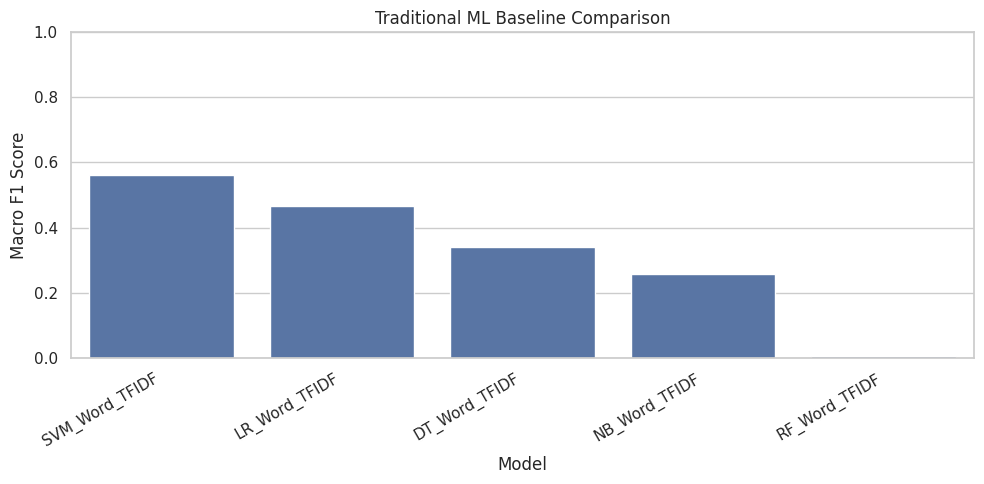


CELL 8 COMPLETED SUCCESSFULLY!


In [13]:

# ==================================================
# CELL 8: TF-IDF + RANDOM FOREST BASELINE
# ==================================================

import os
import time
import joblib
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier

from sklearn.metrics import (
    precision_recall_fscore_support,
    f1_score,
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    hamming_loss
)

# ==================================================
# 1. Configuration
# ==================================================

SEED = 42
OUTPUT_DIR = "/content/jigsaw_research"
MODEL_NAME = "RF_Word_TFIDF"
THRESHOLD = 0.50

DATA_PATH = "/content/jigsaw-toxic-comment-classification-challenge.zip"

os.makedirs(OUTPUT_DIR, exist_ok=True)

assert "train_split" in globals(), "Run Cell 3 first."
assert "val_split" in globals(), "Run Cell 3 first."

# ==================================================
# 2. Reuse TF-IDF Features
# ==================================================

if (
    "X_train_tfidf" not in globals()
    or "X_val_tfidf" not in globals()
):

    tfidf = joblib.load(
        f"{OUTPUT_DIR}/tfidf_word_vectorizer.joblib"
    )

    X_train_tfidf = tfidf.transform(
        train_split["comment_text"].fillna("")
    )

    X_val_tfidf = tfidf.transform(
        val_split["comment_text"].fillna("")
    )

y_train = train_split[LABELS].to_numpy()
y_val = val_split[LABELS].to_numpy()

print("Training:", X_train_tfidf.shape)
print("Validation:", X_val_tfidf.shape)

# ==================================================
# 3. Train Random Forest
# ==================================================

print("\nTraining Random Forest...")

start_time = time.time()

rf_model = OneVsRestClassifier(
    RandomForestClassifier(
        n_estimators=80,
        criterion="gini",
        max_depth=22,
        min_samples_split=8,
        min_samples_leaf=4,
        max_features="sqrt",
        bootstrap=True,
        class_weight=None,
        random_state=SEED,
        n_jobs=-1
    ),
    n_jobs=1
)

rf_model.fit(X_train_tfidf, y_train)

training_time = time.time() - start_time

print("\nTraining completed!")
print(f"Training time: {training_time:.2f} seconds")

# ==================================================
# 4. Predict Validation Probabilities
# ==================================================

y_prob_rf = rf_model.predict_proba(X_val_tfidf)

y_pred_rf = (
    y_prob_rf >= THRESHOLD
).astype(int)

# ==================================================
# 5. Per-Class Evaluation
# ==================================================

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_val,
        y_pred_rf,
        average=None,
        zero_division=0
    )
)

per_class_results = []

for i, label in enumerate(LABELS):

    auc = roc_auc_score(
        y_val[:, i],
        y_prob_rf[:, i]
    )

    ap = average_precision_score(
        y_val[:, i],
        y_prob_rf[:, i]
    )

    per_class_results.append({
        "Label": label,
        "Precision": precision[i],
        "Recall": recall[i],
        "F1": f1[i],
        "ROC_AUC": auc,
        "AP": ap,
        "Support": support[i]
    })

per_class_rf_df = pd.DataFrame(
    per_class_results
)

print("\n========== PER-CLASS PERFORMANCE ==========")

display(per_class_rf_df.round(4))

# ==================================================
# 6. Overall Performance
# ==================================================

results_rf = {
    "Model": MODEL_NAME,

    "Macro_F1": f1_score(
        y_val,
        y_pred_rf,
        average="macro",
        zero_division=0
    ),

    "Micro_F1": f1_score(
        y_val,
        y_pred_rf,
        average="micro",
        zero_division=0
    ),

    "Weighted_F1": f1_score(
        y_val,
        y_pred_rf,
        average="weighted",
        zero_division=0
    ),

    "Macro_ROC_AUC": roc_auc_score(
        y_val,
        y_prob_rf,
        average="macro"
    ),

    "Macro_AP": average_precision_score(
        y_val,
        y_prob_rf,
        average="macro"
    ),

    "Subset_Accuracy": accuracy_score(
        y_val,
        y_pred_rf
    ),

    "Hamming_Loss": hamming_loss(
        y_val,
        y_pred_rf
    ),

    "Threshold": THRESHOLD
}

print("\n========== OVERALL MODEL PERFORMANCE ==========")

for metric, value in results_rf.items():
    if metric != "Model":
        print(f"{metric:20s}: {value:.4f}")

# ==================================================
# 7. Save Model and Predictions
# ==================================================

joblib.dump(
    rf_model,
    f"{OUTPUT_DIR}/random_forest_baseline.joblib"
)

np.savez_compressed(
    f"{OUTPUT_DIR}/RF_Word_TFIDF_validation.npz",
    y_true=y_val,
    y_prob=y_prob_rf,
    y_pred=y_pred_rf
)

per_class_rf_df.to_csv(
    f"{OUTPUT_DIR}/RF_Word_TFIDF_per_class.csv",
    index=False
)

pd.DataFrame([results_rf]).to_csv(
    f"{OUTPUT_DIR}/RF_Word_TFIDF_results.csv",
    index=False
)

# ==================================================
# 8. Update Traditional ML Comparison
# ==================================================

comparison_path = (
    f"{OUTPUT_DIR}/traditional_ml_comparison.csv"
)

comparison = pd.read_csv(comparison_path)

comparison = pd.concat(
    [
        comparison,
        pd.DataFrame([results_rf])
    ],
    ignore_index=True
)

comparison = comparison.drop_duplicates(
    subset=["Model"],
    keep="last"
)

comparison = comparison.sort_values(
    by="Macro_F1",
    ascending=False
).reset_index(drop=True)

comparison.to_csv(
    comparison_path,
    index=False
)

print("\n========== FIVE-MODEL COMPARISON ==========")

display(
    comparison[
        [
            "Model",
            "Macro_F1",
            "Micro_F1",
            "Macro_ROC_AUC",
            "Macro_AP"
        ]
    ].round(4)
)

# ==================================================
# 9. Visualize Model Comparison
# ==================================================

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Macro_F1"
)

plt.title("Traditional ML Baseline Comparison")
plt.xlabel("Model")
plt.ylabel("Macro F1 Score")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

print("\nCELL 8 COMPLETED SUCCESSFULLY!")


In [14]:

# ==================================================
# CELL 9: CHARACTER TF-IDF + LOGISTIC REGRESSION
# ==================================================

import os
import time
import joblib
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

from sklearn.metrics import (
    precision_recall_fscore_support,
    f1_score,
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    hamming_loss
)

# ==================================================
# 1. Configuration
# ==================================================

SEED = 42
OUTPUT_DIR = "/content/jigsaw_research"
DATA_PATH = "/content/jigsaw-toxic-comment-classification-challenge.zip"

MODEL_NAME = "LR_Char_TFIDF"
THRESHOLD = 0.50

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ==================================================
# 2. Prepare Data
# ==================================================

if "train_split" not in globals():
    train_split = pd.read_csv(
        f"{OUTPUT_DIR}/train_split.csv"
    )

if "val_split" not in globals():
    val_split = pd.read_csv(
        f"{OUTPUT_DIR}/validation_split.csv"
    )

LABELS = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

X_train_text = train_split["comment_text"].fillna("")
X_val_text = val_split["comment_text"].fillna("")

y_train = train_split[LABELS].to_numpy()
y_val = val_split[LABELS].to_numpy()

print("Training samples:", len(X_train_text))
print("Validation samples:", len(X_val_text))

# ==================================================
# 3. Character-Level TF-IDF
# ==================================================

print("\nExtracting character TF-IDF features...")

start_time = time.time()

char_tfidf = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    lowercase=True,
    min_df=3,
    max_df=0.995,
    max_features=150000,
    sublinear_tf=True,
    dtype=np.float32
)

X_train_char = char_tfidf.fit_transform(
    X_train_text
)

X_val_char = char_tfidf.transform(
    X_val_text
)

print("Training feature shape:", X_train_char.shape)
print("Validation feature shape:", X_val_char.shape)

# ==================================================
# 4. Train Logistic Regression
# ==================================================

print("\nTraining Character TF-IDF Logistic Regression...")

lr_char_model = OneVsRestClassifier(
    LogisticRegression(
        C=1.0,
        max_iter=1000,
        solver="liblinear",
        random_state=SEED
    ),
    n_jobs=1
)

lr_char_model.fit(X_train_char, y_train)

training_time = time.time() - start_time

print("\nTraining completed!")
print(f"Total processing time: {training_time:.2f} seconds")

# ==================================================
# 5. Validation Predictions
# ==================================================

y_prob_char = lr_char_model.predict_proba(
    X_val_char
)

y_pred_char = (
    y_prob_char >= THRESHOLD
).astype(int)

# ==================================================
# 6. Per-Class Performance
# ==================================================

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_val,
        y_pred_char,
        average=None,
        zero_division=0
    )
)

per_class_results = []

for i, label in enumerate(LABELS):

    per_class_results.append({
        "Label": label,
        "Precision": precision[i],
        "Recall": recall[i],
        "F1": f1[i],
        "ROC_AUC": roc_auc_score(
            y_val[:, i],
            y_prob_char[:, i]
        ),
        "AP": average_precision_score(
            y_val[:, i],
            y_prob_char[:, i]
        ),
        "Support": support[i]
    })

per_class_char_df = pd.DataFrame(
    per_class_results
)

print("\n========== PER-CLASS PERFORMANCE ==========")
display(per_class_char_df.round(4))

# ==================================================
# 7. Overall Performance
# ==================================================

results_char = {
    "Model": MODEL_NAME,

    "Macro_F1": f1_score(
        y_val,
        y_pred_char,
        average="macro",
        zero_division=0
    ),

    "Micro_F1": f1_score(
        y_val,
        y_pred_char,
        average="micro",
        zero_division=0
    ),

    "Weighted_F1": f1_score(
        y_val,
        y_pred_char,
        average="weighted",
        zero_division=0
    ),

    "Macro_ROC_AUC": roc_auc_score(
        y_val,
        y_prob_char,
        average="macro"
    ),

    "Macro_AP": average_precision_score(
        y_val,
        y_prob_char,
        average="macro"
    ),

    "Subset_Accuracy": accuracy_score(
        y_val,
        y_pred_char
    ),

    "Hamming_Loss": hamming_loss(
        y_val,
        y_pred_char
    ),

    "Threshold": THRESHOLD
}

print("\n========== OVERALL MODEL PERFORMANCE ==========")

for metric, value in results_char.items():
    if metric != "Model":
        print(f"{metric:20s}: {value:.4f}")

# ==================================================
# 8. Save Model and Results
# ==================================================

joblib.dump(
    char_tfidf,
    f"{OUTPUT_DIR}/char_tfidf_vectorizer.joblib"
)

joblib.dump(
    lr_char_model,
    f"{OUTPUT_DIR}/lr_char_tfidf_model.joblib"
)

np.savez_compressed(
    f"{OUTPUT_DIR}/LR_Char_TFIDF_validation.npz",
    y_true=y_val,
    y_prob=y_prob_char,
    y_pred=y_pred_char
)

per_class_char_df.to_csv(
    f"{OUTPUT_DIR}/LR_Char_TFIDF_per_class.csv",
    index=False
)

pd.DataFrame([results_char]).to_csv(
    f"{OUTPUT_DIR}/LR_Char_TFIDF_results.csv",
    index=False
)

# ==================================================
# 9. Word vs Character Comparison
# ==================================================

word_results = pd.read_csv(
    f"{OUTPUT_DIR}/LR_Word_TFIDF_results.csv"
)

comparison = pd.concat(
    [
        word_results,
        pd.DataFrame([results_char])
    ],
    ignore_index=True
)

comparison.to_csv(
    f"{OUTPUT_DIR}/LR_Word_vs_Char.csv",
    index=False
)

print("\n========== WORD VS CHARACTER TF-IDF ==========")

display(
    comparison[
        [
            "Model",
            "Macro_F1",
            "Micro_F1",
            "Macro_ROC_AUC",
            "Macro_AP"
        ]
    ].round(4)
)

print("\n========== IMPROVEMENT ANALYSIS ==========")

word_f1 = word_results["Macro_F1"].iloc[0]
char_f1 = results_char["Macro_F1"]

difference = char_f1 - word_f1

print(f"Word TF-IDF Macro F1 : {word_f1:.4f}")
print(f"Char TF-IDF Macro F1 : {char_f1:.4f}")
print(f"Absolute difference  : {difference:+.4f}")

print("\nCELL 9 COMPLETED SUCCESSFULLY!")


Training samples: 127656
Validation samples: 31915

Extracting character TF-IDF features...
Training feature shape: (127656, 150000)
Validation feature shape: (31915, 150000)

Training Character TF-IDF Logistic Regression...

Training completed!
Total processing time: 307.27 seconds

========== PER-CLASS PERFORMANCE ==========


,Label,Precision,Recall,F1,ROC_AUC,AP,Support
0,toxic,0.9319,0.6038,0.7328,0.9769,0.8807,3059
1,severe_toxic,0.5638,0.2633,0.3590,0.9870,0.4755,319
2,obscene,0.9324,0.6450,0.7625,0.9866,0.8909,1690
3,threat,0.8571,0.0625,0.1165,0.9812,0.3897,96
4,insult,0.8557,0.5460,0.6667,0.9800,0.7992,1575
5,identity_hate,0.7193,0.1459,0.2426,0.9787,0.4587,281



========== OVERALL MODEL PERFORMANCE ==========
Macro_F1            : 0.4800
Micro_F1            : 0.6898
Weighted_F1         : 0.6801
Macro_ROC_AUC       : 0.9817
Macro_AP            : 0.6491
Subset_Accuracy     : 0.9214
Hamming_Loss        : 0.0185
Threshold           : 0.5000

========== WORD VS CHARACTER TF-IDF ==========


,Model,Macro_F1,Micro_F1,Macro_ROC_AUC,Macro_AP
0,LR_Word_TFIDF,0.4663,0.6612,0.9783,0.6206
1,LR_Char_TFIDF,0.4800,0.6898,0.9817,0.6491



========== IMPROVEMENT ANALYSIS ==========
Word TF-IDF Macro F1 : 0.4663
Char TF-IDF Macro F1 : 0.4800
Absolute difference  : +0.0137

CELL 9 COMPLETED SUCCESSFULLY!


In [15]:

# ==================================================
# CELL 10: CHARACTER TF-IDF + LINEAR SVM
# ==================================================

import os
import time
import joblib
import numpy as np
import pandas as pd

from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsRestClassifier

from sklearn.metrics import (
    precision_recall_fscore_support,
    f1_score,
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    hamming_loss
)

# ==================================================
# 1. Configuration
# ==================================================

SEED = 42
OUTPUT_DIR = "/content/jigsaw_research"

DATA_PATH = "/content/jigsaw-toxic-comment-classification-challenge.zip"

MODEL_NAME = "SVM_Char_TFIDF"

os.makedirs(OUTPUT_DIR, exist_ok=True)

LABELS = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

# ==================================================
# 2. Load Fixed Train/Validation Split
# ==================================================

if "train_split" not in globals():
    train_split = pd.read_csv(
        f"{OUTPUT_DIR}/train_split.csv"
    )

if "val_split" not in globals():
    val_split = pd.read_csv(
        f"{OUTPUT_DIR}/validation_split.csv"
    )

y_train = train_split[LABELS].to_numpy()
y_val = val_split[LABELS].to_numpy()

# ==================================================
# 3. Reuse Character TF-IDF From Cell 9
# ==================================================

if (
    "X_train_char" not in globals()
    or "X_val_char" not in globals()
):

    print("Loading saved character TF-IDF vectorizer...")

    char_tfidf = joblib.load(
        f"{OUTPUT_DIR}/char_tfidf_vectorizer.joblib"
    )

    X_train_char = char_tfidf.transform(
        train_split["comment_text"].fillna("")
    )

    X_val_char = char_tfidf.transform(
        val_split["comment_text"].fillna("")
    )

print("Training:", X_train_char.shape)
print("Validation:", X_val_char.shape)

# ==================================================
# 4. Train Character-Level SVM
# ==================================================

print("\nTraining Character TF-IDF + Linear SVM...")

start_time = time.time()

svm_char_model = OneVsRestClassifier(
    LinearSVC(
        C=1.0,
        max_iter=5000,
        tol=1e-4,
        dual="auto",
        random_state=SEED
    ),
    n_jobs=1
)

svm_char_model.fit(X_train_char, y_train)

training_time = time.time() - start_time

print("\nTraining completed!")
print(f"Training time: {training_time:.2f} seconds")

# ==================================================
# 5. Predict Validation Scores
# ==================================================

# Linear SVM produces decision scores, not probabilities.

y_score_char_svm = svm_char_model.decision_function(
    X_val_char
)

y_pred_char_svm = (
    y_score_char_svm > 0
).astype(int)

# ==================================================
# 6. Evaluate Per-Class Performance
# ==================================================

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_val,
        y_pred_char_svm,
        average=None,
        zero_division=0
    )
)

per_class_results = []

for i, label in enumerate(LABELS):

    per_class_results.append({
        "Label": label,
        "Precision": precision[i],
        "Recall": recall[i],
        "F1": f1[i],
        "ROC_AUC": roc_auc_score(
            y_val[:, i],
            y_score_char_svm[:, i]
        ),
        "AP": average_precision_score(
            y_val[:, i],
            y_score_char_svm[:, i]
        ),
        "Support": support[i]
    })

per_class_char_svm_df = pd.DataFrame(
    per_class_results
)

print("\n========== PER-CLASS PERFORMANCE ==========")

display(per_class_char_svm_df.round(4))

# ==================================================
# 7. Calculate Overall Metrics
# ==================================================

results_char_svm = {
    "Model": MODEL_NAME,

    "Macro_F1": f1_score(
        y_val,
        y_pred_char_svm,
        average="macro",
        zero_division=0
    ),

    "Micro_F1": f1_score(
        y_val,
        y_pred_char_svm,
        average="micro",
        zero_division=0
    ),

    "Weighted_F1": f1_score(
        y_val,
        y_pred_char_svm,
        average="weighted",
        zero_division=0
    ),

    "Macro_ROC_AUC": roc_auc_score(
        y_val,
        y_score_char_svm,
        average="macro"
    ),

    "Macro_AP": average_precision_score(
        y_val,
        y_score_char_svm,
        average="macro"
    ),

    "Subset_Accuracy": accuracy_score(
        y_val,
        y_pred_char_svm
    ),

    "Hamming_Loss": hamming_loss(
        y_val,
        y_pred_char_svm
    ),

    "Threshold": 0.0
}

print("\n========== OVERALL MODEL PERFORMANCE ==========")

for metric, value in results_char_svm.items():
    if metric != "Model":
        print(f"{metric:20s}: {value:.4f}")

# ==================================================
# 8. Save Model and Predictions
# ==================================================

joblib.dump(
    svm_char_model,
    f"{OUTPUT_DIR}/svm_char_tfidf_model.joblib"
)

np.savez_compressed(
    f"{OUTPUT_DIR}/SVM_Char_TFIDF_validation.npz",
    y_true=y_val,
    y_score=y_score_char_svm,
    y_pred=y_pred_char_svm
)

per_class_char_svm_df.to_csv(
    f"{OUTPUT_DIR}/SVM_Char_TFIDF_per_class.csv",
    index=False
)

pd.DataFrame([results_char_svm]).to_csv(
    f"{OUTPUT_DIR}/SVM_Char_TFIDF_results.csv",
    index=False
)

# ==================================================
# 9. Word vs Character SVM Comparison
# ==================================================

word_svm_results = pd.read_csv(
    f"{OUTPUT_DIR}/SVM_Word_TFIDF_results.csv"
)

svm_comparison = pd.concat(
    [
        word_svm_results,
        pd.DataFrame([results_char_svm])
    ],
    ignore_index=True
)

svm_comparison.to_csv(
    f"{OUTPUT_DIR}/SVM_Word_vs_Char.csv",
    index=False
)

print("\n========== WORD VS CHARACTER SVM ==========")

display(
    svm_comparison[
        [
            "Model",
            "Macro_F1",
            "Micro_F1",
            "Macro_ROC_AUC",
            "Macro_AP"
        ]
    ].round(4)
)

# ==================================================
# 10. Per-Class F1 Improvement
# ==================================================

word_per_class = pd.read_csv(
    f"{OUTPUT_DIR}/SVM_Word_TFIDF_per_class.csv"
)

class_comparison = pd.DataFrame({
    "Label": LABELS,
    "Word_F1": word_per_class["F1"].values,
    "Char_F1": per_class_char_svm_df["F1"].values
})

class_comparison["F1_Difference"] = (
    class_comparison["Char_F1"]
    - class_comparison["Word_F1"]
)

print("\n========== PER-CLASS F1 DIFFERENCE ==========")

display(class_comparison.round(4))

class_comparison.to_csv(
    f"{OUTPUT_DIR}/SVM_Word_vs_Char_PerClass.csv",
    index=False
)

# ==================================================
# 11. Overall Improvement
# ==================================================

word_f1 = word_svm_results["Macro_F1"].iloc[0]
char_f1 = results_char_svm["Macro_F1"]

print("\n========== IMPROVEMENT ANALYSIS ==========")

print(f"Word SVM Macro F1 : {word_f1:.4f}")
print(f"Char SVM Macro F1 : {char_f1:.4f}")
print(f"Absolute change   : {char_f1 - word_f1:+.4f}")

print("\nCELL 10 COMPLETED SUCCESSFULLY!")


Training: (127656, 150000)
Validation: (31915, 150000)

Training Character TF-IDF + Linear SVM...

Training completed!
Training time: 70.15 seconds

========== PER-CLASS PERFORMANCE ==========


,Label,Precision,Recall,F1,ROC_AUC,AP,Support
0,toxic,0.8878,0.7035,0.7850,0.9751,0.8837,3059
1,severe_toxic,0.5604,0.3197,0.4072,0.9782,0.4612,319
2,obscene,0.8902,0.7391,0.8076,0.9851,0.8894,1690
3,threat,0.6047,0.2708,0.3741,0.9648,0.4121,96
4,insult,0.7960,0.6292,0.7028,0.9748,0.7888,1575
5,identity_hate,0.6567,0.3132,0.4241,0.9676,0.4611,281



========== OVERALL MODEL PERFORMANCE ==========
Macro_F1            : 0.5835
Micro_F1            : 0.7402
Weighted_F1         : 0.7348
Macro_ROC_AUC       : 0.9743
Macro_AP            : 0.6494
Subset_Accuracy     : 0.9234
Hamming_Loss        : 0.0169
Threshold           : 0.0000

========== WORD VS CHARACTER SVM ==========


,Model,Macro_F1,Micro_F1,Macro_ROC_AUC,Macro_AP
0,SVM_Word_TFIDF,0.5629,0.7236,0.9671,0.6288
1,SVM_Char_TFIDF,0.5835,0.7402,0.9743,0.6494



========== PER-CLASS F1 DIFFERENCE ==========


,Label,Word_F1,Char_F1,F1_Difference
0,toxic,0.7750,0.7850,0.0100
1,severe_toxic,0.4211,0.4072,-0.0139
2,obscene,0.7887,0.8076,0.0189
3,threat,0.3571,0.3741,0.0170
4,insult,0.6787,0.7028,0.0241
5,identity_hate,0.3570,0.4241,0.0671



========== IMPROVEMENT ANALYSIS ==========
Word SVM Macro F1 : 0.5629
Char SVM Macro F1 : 0.5835
Absolute change   : +0.0205

CELL 10 COMPLETED SUCCESSFULLY!


In [16]:

# ==================================================
# CELL 11: COMBINED WORD + CHARACTER TF-IDF + SVM
# ==================================================

import os
import time
import joblib
import numpy as np
import pandas as pd

from scipy.sparse import hstack

from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsRestClassifier

from sklearn.metrics import (
    precision_recall_fscore_support,
    f1_score,
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    hamming_loss
)

# ==================================================
# 1. Configuration
# ==================================================

SEED = 42

DATA_PATH = "/content/jigsaw-toxic-comment-classification-challenge.zip"

OUTPUT_DIR = "/content/jigsaw_research"
MODEL_NAME = "SVM_Word_Char_TFIDF"

os.makedirs(OUTPUT_DIR, exist_ok=True)

LABELS = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

# ==================================================
# 2. Load Fixed Training and Validation Splits
# ==================================================

if "train_split" not in globals():
    train_split = pd.read_csv(
        f"{OUTPUT_DIR}/train_split.csv"
    )

if "val_split" not in globals():
    val_split = pd.read_csv(
        f"{OUTPUT_DIR}/validation_split.csv"
    )

X_train_text = train_split["comment_text"].fillna("")
X_val_text = val_split["comment_text"].fillna("")

y_train = train_split[LABELS].to_numpy()
y_val = val_split[LABELS].to_numpy()

print("Training samples:", len(X_train_text))
print("Validation samples:", len(X_val_text))

# ==================================================
# 3. Load Existing TF-IDF Representations
# ==================================================

if "X_train_tfidf" not in globals():

    word_tfidf = joblib.load(
        f"{OUTPUT_DIR}/tfidf_word_vectorizer.joblib"
    )

    X_train_tfidf = word_tfidf.transform(
        X_train_text
    )

    X_val_tfidf = word_tfidf.transform(
        X_val_text
    )

if "X_train_char" not in globals():

    char_tfidf = joblib.load(
        f"{OUTPUT_DIR}/char_tfidf_vectorizer.joblib"
    )

    X_train_char = char_tfidf.transform(
        X_train_text
    )

    X_val_char = char_tfidf.transform(
        X_val_text
    )

print("\nWord features:", X_train_tfidf.shape)
print("Character features:", X_train_char.shape)

# ==================================================
# 4. Combine Word and Character Features
# ==================================================

print("\nCombining Word + Character TF-IDF...")

# Give each normalized feature block equal initial weight.
# Avoid converting sparse matrices to dense arrays.

weight = 1.0 / np.sqrt(2.0)

X_train_combined = hstack(
    [
        X_train_tfidf * weight,
        X_train_char * weight
    ],
    format="csr",
    dtype=np.float32
)

X_val_combined = hstack(
    [
        X_val_tfidf * weight,
        X_val_char * weight
    ],
    format="csr",
    dtype=np.float32
)

print("Combined training shape:", X_train_combined.shape)
print("Combined validation shape:", X_val_combined.shape)

# ==================================================
# 5. Train Combined Linear SVM
# ==================================================

print("\nTraining Word + Character Linear SVM...")

start_time = time.time()

svm_combined_model = OneVsRestClassifier(
    LinearSVC(
        C=1.0,
        max_iter=5000,
        tol=1e-4,
        dual="auto",
        random_state=SEED
    ),
    n_jobs=1
)

svm_combined_model.fit(
    X_train_combined,
    y_train
)

training_time = time.time() - start_time

print("\nTraining completed!")
print(f"Training time: {training_time:.2f} seconds")

# ==================================================
# 6. Validation Predictions
# ==================================================

y_score_combined = (
    svm_combined_model.decision_function(
        X_val_combined
    )
)

# Default SVM decision boundary
y_pred_combined = (
    y_score_combined > 0
).astype(int)

# ==================================================
# 7. Per-Class Performance
# ==================================================

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_val,
        y_pred_combined,
        average=None,
        zero_division=0
    )
)

per_class_results = []

for i, label in enumerate(LABELS):

    per_class_results.append({
        "Label": label,
        "Precision": precision[i],
        "Recall": recall[i],
        "F1": f1[i],
        "ROC_AUC": roc_auc_score(
            y_val[:, i],
            y_score_combined[:, i]
        ),
        "AP": average_precision_score(
            y_val[:, i],
            y_score_combined[:, i]
        ),
        "Support": support[i]
    })

per_class_combined_df = pd.DataFrame(
    per_class_results
)

print("\n========== PER-CLASS PERFORMANCE ==========")

display(per_class_combined_df.round(4))

# ==================================================
# 8. Overall Performance
# ==================================================

results_combined = {
    "Model": MODEL_NAME,

    "Macro_F1": f1_score(
        y_val,
        y_pred_combined,
        average="macro",
        zero_division=0
    ),

    "Micro_F1": f1_score(
        y_val,
        y_pred_combined,
        average="micro",
        zero_division=0
    ),

    "Weighted_F1": f1_score(
        y_val,
        y_pred_combined,
        average="weighted",
        zero_division=0
    ),

    "Macro_ROC_AUC": roc_auc_score(
        y_val,
        y_score_combined,
        average="macro"
    ),

    "Macro_AP": average_precision_score(
        y_val,
        y_score_combined,
        average="macro"
    ),

    "Subset_Accuracy": accuracy_score(
        y_val,
        y_pred_combined
    ),

    "Hamming_Loss": hamming_loss(
        y_val,
        y_pred_combined
    ),

    "Threshold": 0.0
}

print("\n========== OVERALL MODEL PERFORMANCE ==========")

for metric, value in results_combined.items():

    if metric != "Model":
        print(f"{metric:20s}: {value:.4f}")

# ==================================================
# 9. Save Model and Predictions
# ==================================================

joblib.dump(
    svm_combined_model,
    f"{OUTPUT_DIR}/svm_word_char_model.joblib"
)

np.savez_compressed(
    f"{OUTPUT_DIR}/SVM_Word_Char_TFIDF_validation.npz",
    y_true=y_val,
    y_score=y_score_combined,
    y_pred=y_pred_combined
)

per_class_combined_df.to_csv(
    f"{OUTPUT_DIR}/SVM_Word_Char_TFIDF_per_class.csv",
    index=False
)

pd.DataFrame([results_combined]).to_csv(
    f"{OUTPUT_DIR}/SVM_Word_Char_TFIDF_results.csv",
    index=False
)

# ==================================================
# 10. Compare All Three SVM Representations
# ==================================================

word_results = pd.read_csv(
    f"{OUTPUT_DIR}/SVM_Word_TFIDF_results.csv"
)

char_results = pd.read_csv(
    f"{OUTPUT_DIR}/SVM_Char_TFIDF_results.csv"
)

comparison = pd.concat(
    [
        word_results,
        char_results,
        pd.DataFrame([results_combined])
    ],
    ignore_index=True
)

comparison = comparison.sort_values(
    by="Macro_F1",
    ascending=False
).reset_index(drop=True)

comparison.to_csv(
    f"{OUTPUT_DIR}/SVM_Feature_Comparison.csv",
    index=False
)

print("\n========== SVM FEATURE COMPARISON ==========")

display(
    comparison[
        [
            "Model",
            "Macro_F1",
            "Micro_F1",
            "Macro_ROC_AUC",
            "Macro_AP"
        ]
    ].round(4)
)

# ==================================================
# 11. Compare Per-Class F1
# ==================================================

word_class = pd.read_csv(
    f"{OUTPUT_DIR}/SVM_Word_TFIDF_per_class.csv"
)

char_class = pd.read_csv(
    f"{OUTPUT_DIR}/SVM_Char_TFIDF_per_class.csv"
)

class_comparison = pd.DataFrame({
    "Label": LABELS,
    "Word_F1": word_class["F1"].values,
    "Char_F1": char_class["F1"].values,
    "Combined_F1": per_class_combined_df["F1"].values
})

class_comparison["Change_vs_Char"] = (
    class_comparison["Combined_F1"]
    - class_comparison["Char_F1"]
)

print("\n========== PER-CLASS COMPARISON ==========")

display(class_comparison.round(4))

class_comparison.to_csv(
    f"{OUTPUT_DIR}/SVM_Three_Features_PerClass.csv",
    index=False
)

# ==================================================
# 12. Improvement Analysis
# ==================================================

baseline_f1 = word_results["Macro_F1"].iloc[0]
char_f1 = char_results["Macro_F1"].iloc[0]
combined_f1 = results_combined["Macro_F1"]

print("\n========== IMPROVEMENT ANALYSIS ==========")

print(f"Word SVM F1     : {baseline_f1:.4f}")
print(f"Character SVM F1: {char_f1:.4f}")
print(f"Combined SVM F1 : {combined_f1:.4f}")

print(
    f"Change vs Word  : {combined_f1 - baseline_f1:+.4f}"
)

print(
    f"Change vs Char  : {combined_f1 - char_f1:+.4f}"
)

print("\nCELL 11 COMPLETED SUCCESSFULLY!")


Training samples: 127656
Validation samples: 31915

Word features: (127656, 100000)
Character features: (127656, 150000)

Combining Word + Character TF-IDF...
Combined training shape: (127656, 250000)
Combined validation shape: (31915, 250000)

Training Word + Character Linear SVM...

Training completed!
Training time: 42.42 seconds

========== PER-CLASS PERFORMANCE ==========


,Label,Precision,Recall,F1,ROC_AUC,AP,Support
0,toxic,0.8889,0.7038,0.7856,0.9777,0.8905,3059
1,severe_toxic,0.5625,0.3386,0.4227,0.9808,0.4654,319
2,obscene,0.8918,0.7414,0.8097,0.9865,0.8950,1690
3,threat,0.6136,0.2812,0.3857,0.9670,0.4444,96
4,insult,0.8026,0.6375,0.7105,0.9756,0.7890,1575
5,identity_hate,0.6154,0.2847,0.3893,0.9674,0.4562,281



========== OVERALL MODEL PERFORMANCE ==========
Macro_F1            : 0.5839
Micro_F1            : 0.7421
Weighted_F1         : 0.7367
Macro_ROC_AUC       : 0.9758
Macro_AP            : 0.6568
Subset_Accuracy     : 0.9242
Hamming_Loss        : 0.0168
Threshold           : 0.0000

========== SVM FEATURE COMPARISON ==========


,Model,Macro_F1,Micro_F1,Macro_ROC_AUC,Macro_AP
0,SVM_Word_Char_TFIDF,0.5839,0.7421,0.9758,0.6568
1,SVM_Char_TFIDF,0.5835,0.7402,0.9743,0.6494
2,SVM_Word_TFIDF,0.5629,0.7236,0.9671,0.6288



========== PER-CLASS COMPARISON ==========


,Label,Word_F1,Char_F1,Combined_F1,Change_vs_Char
0,toxic,0.7750,0.7850,0.7856,0.0007
1,severe_toxic,0.4211,0.4072,0.4227,0.0155
2,obscene,0.7887,0.8076,0.8097,0.0021
3,threat,0.3571,0.3741,0.3857,0.0116
4,insult,0.6787,0.7028,0.7105,0.0077
5,identity_hate,0.3570,0.4241,0.3893,-0.0348



========== IMPROVEMENT ANALYSIS ==========
Word SVM F1     : 0.5629
Character SVM F1: 0.5835
Combined SVM F1 : 0.5839
Change vs Word  : +0.0210
Change vs Char  : +0.0005

CELL 11 COMPLETED SUCCESSFULLY!


Threshold tuning samples: 15957
Audit samples: 15958

Audit positive-label counts:
toxic            1530
severe_toxic      160
obscene           845
threat             48
insult            788
identity_hate     141
dtype: int64

Processing: LR_Word_TFIDF
Default Macro F1: 0.4539
Tuned Macro F1  : 0.5770
F1 change       : +0.1231

Processing: NB_Word_TFIDF
Default Macro F1: 0.2601
Tuned Macro F1  : 0.4553
F1 change       : +0.1952

Processing: SVM_Word_TFIDF
Default Macro F1: 0.5466
Tuned Macro F1  : 0.6082
F1 change       : +0.0616

Processing: DT_Word_TFIDF
Default Macro F1: 0.3067
Tuned Macro F1  : 0.3815
F1 change       : +0.0748

Processing: RF_Word_TFIDF
Default Macro F1: 0.0032
Tuned Macro F1  : 0.5502
F1 change       : +0.5470

Processing: LR_Char_TFIDF
Default Macro F1: 0.4664
Tuned Macro F1  : 0.6091
F1 change       : +0.1427

Processing: SVM_Char_TFIDF
Default Macro F1: 0.5744
Tuned Macro F1  : 0.6220
F1 change       : +0.0476

Processing: SVM_Word_Char_TFIDF
Default Macro F1

,Model,Default_Macro_F1,Tuned_Macro_F1,F1_Change,Tuned_Micro_F1,Macro_AP
0,SVM_Word_Char_TFIDF,0.5668,0.6251,0.0583,0.7519,0.6431
1,SVM_Char_TFIDF,0.5744,0.6220,0.0476,0.7468,0.6380
2,LR_Char_TFIDF,0.4664,0.6091,0.1427,0.7405,0.6357
3,SVM_Word_TFIDF,0.5466,0.6082,0.0616,0.7384,0.6148
4,LR_Word_TFIDF,0.4539,0.5770,0.1231,0.7260,0.6083
5,RF_Word_TFIDF,0.0032,0.5502,0.5470,0.6934,0.5589
6,NB_Word_TFIDF,0.2601,0.4553,0.1952,0.6215,0.4476
7,DT_Word_TFIDF,0.3067,0.3815,0.0748,0.4837,0.2884



========== COMBINED SVM PER-CLASS RESULTS ==========


,Label,Threshold,Default_F1,Tuned_F1,Tuned_Precision,Tuned_Recall,Support
0,toxic,-0.2013,0.7851,0.8015,0.8365,0.7693,1530
1,severe_toxic,-0.3848,0.4436,0.4882,0.4208,0.5812,160
2,obscene,-0.3147,0.8055,0.8141,0.8199,0.8083,845
3,threat,-0.5332,0.2941,0.4299,0.3898,0.4792,48
4,insult,-0.3152,0.7100,0.7277,0.6969,0.7614,788
5,identity_hate,-0.3744,0.3627,0.4895,0.4828,0.4965,141


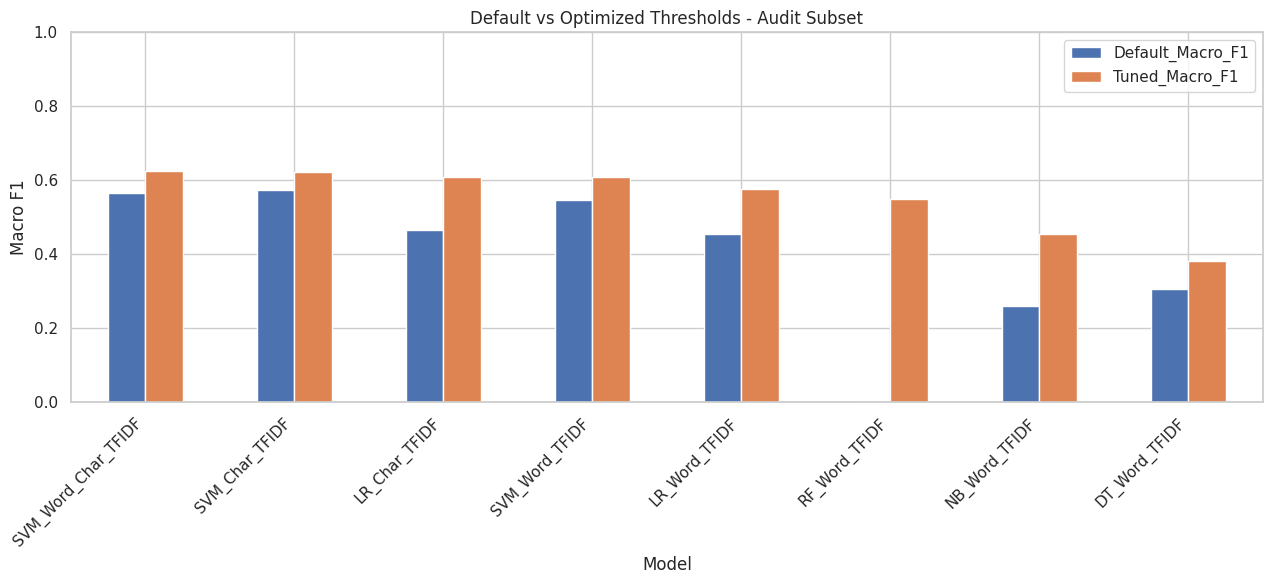


CELL 12 COMPLETED SUCCESSFULLY!


In [17]:

# ==================================================
# CELL 12: PER-CLASS THRESHOLD OPTIMIZATION
# ==================================================

import os
import json
import numpy as np
import pandas as pd

from iterstrat.ml_stratifiers import (
    MultilabelStratifiedShuffleSplit
)

from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

# ==================================================
# 1. Configuration
# ==================================================

OUTPUT_DIR = "/content/jigsaw_research"
SEED = 42

LABELS = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

# Models saved during previous experiments
MODELS = {
    "LR_Word_TFIDF": ("y_prob", 0.5),
    "NB_Word_TFIDF": ("y_prob", 0.5),
    "SVM_Word_TFIDF": ("y_score", 0.0),
    "DT_Word_TFIDF": ("y_prob", 0.5),
    "RF_Word_TFIDF": ("y_prob", 0.5),
    "LR_Char_TFIDF": ("y_prob", 0.5),
    "SVM_Char_TFIDF": ("y_score", 0.0),
    "SVM_Word_Char_TFIDF": ("y_score", 0.0)
}

# ==================================================
# 2. Load Validation Labels
# ==================================================

val_split = pd.read_csv(
    f"{OUTPUT_DIR}/validation_split.csv"
)

y_val = val_split[LABELS].to_numpy(dtype=int)

# ==================================================
# 3. Split Validation into Tuning and Audit Parts
# ==================================================

splitter = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=SEED
)

tune_idx, audit_idx = next(
    splitter.split(
        np.zeros(len(y_val)),
        y_val
    )
)

y_tune = y_val[tune_idx]
y_audit = y_val[audit_idx]

print("Threshold tuning samples:", len(tune_idx))
print("Audit samples:", len(audit_idx))

print("\nAudit positive-label counts:")
print(pd.Series(y_audit.sum(axis=0), index=LABELS))

np.savez_compressed(
    f"{OUTPUT_DIR}/threshold_split_indices.npz",
    tune_idx=tune_idx,
    audit_idx=audit_idx
)

# ==================================================
# 4. Find F1-Optimal Threshold for One Label
# ==================================================

def find_best_threshold(y_true, scores, default_threshold):

    if len(np.unique(y_true)) < 2:
        return float(default_threshold)

    precision, recall, thresholds = (
        precision_recall_curve(y_true, scores)
    )

    if len(thresholds) == 0:
        return float(default_threshold)

    # Last precision-recall point has no threshold
    p = precision[:-1]
    r = recall[:-1]

    f1_values = (
        2 * p * r / np.maximum(p + r, 1e-12)
    )

    best_index = int(np.argmax(f1_values))

    return float(thresholds[best_index])

# ==================================================
# 5. Evaluate Baseline and Tuned Thresholds
# ==================================================

all_results = []
all_thresholds = {}

for model_name, (score_key, default_threshold) in MODELS.items():

    print("\n" + "=" * 55)
    print("Processing:", model_name)

    prediction_path = (
        f"{OUTPUT_DIR}/{model_name}_validation.npz"
    )

    assert os.path.exists(prediction_path), (
        f"Missing prediction file: {prediction_path}"
    )

    with np.load(prediction_path) as saved:
        scores = saved[score_key].copy()
        saved_y = saved["y_true"].copy()

    assert scores.shape == y_val.shape
    assert np.array_equal(saved_y, y_val), (
        f"Validation label mismatch for {model_name}"
    )

    scores_tune = scores[tune_idx]
    scores_audit = scores[audit_idx]

    # Default predictions
    if score_key == "y_score":
        default_pred = (
            scores_audit > default_threshold
        ).astype(int)
    else:
        default_pred = (
            scores_audit >= default_threshold
        ).astype(int)

    # Optimize each label independently
    thresholds = []

    for j in range(len(LABELS)):

        threshold = find_best_threshold(
            y_tune[:, j],
            scores_tune[:, j],
            default_threshold
        )

        thresholds.append(threshold)

    thresholds = np.array(thresholds)

    # Predictions using tuned thresholds
    tuned_pred = (
        scores_audit >= thresholds
    ).astype(int)

    # Same audit samples for both metrics
    default_macro_f1 = f1_score(
        y_audit,
        default_pred,
        average="macro",
        zero_division=0
    )

    tuned_macro_f1 = f1_score(
        y_audit,
        tuned_pred,
        average="macro",
        zero_division=0
    )

    tuned_micro_f1 = f1_score(
        y_audit,
        tuned_pred,
        average="micro",
        zero_division=0
    )

    macro_ap = average_precision_score(
        y_audit,
        scores_audit,
        average="macro"
    )

    all_results.append({
        "Model": model_name,
        "Default_Macro_F1": default_macro_f1,
        "Tuned_Macro_F1": tuned_macro_f1,
        "F1_Change": tuned_macro_f1 - default_macro_f1,
        "Tuned_Micro_F1": tuned_micro_f1,
        "Macro_AP": macro_ap
    })

    all_thresholds[model_name] = {
        label: float(thresholds[j])
        for j, label in enumerate(LABELS)
    }

    # Per-class comparison on audit subset
    default_f1 = f1_score(
        y_audit, default_pred,
        average=None, zero_division=0
    )

    tuned_f1 = f1_score(
        y_audit, tuned_pred,
        average=None, zero_division=0
    )

    tuned_precision = precision_score(
        y_audit, tuned_pred,
        average=None, zero_division=0
    )

    tuned_recall = recall_score(
        y_audit, tuned_pred,
        average=None, zero_division=0
    )

    per_class = pd.DataFrame({
        "Label": LABELS,
        "Threshold": thresholds,
        "Default_F1": default_f1,
        "Tuned_F1": tuned_f1,
        "Tuned_Precision": tuned_precision,
        "Tuned_Recall": tuned_recall,
        "Support": y_audit.sum(axis=0)
    })

    per_class.to_csv(
        f"{OUTPUT_DIR}/{model_name}_threshold_perclass.csv",
        index=False
    )

    print(f"Default Macro F1: {default_macro_f1:.4f}")
    print(f"Tuned Macro F1  : {tuned_macro_f1:.4f}")
    print(f"F1 change       : {tuned_macro_f1-default_macro_f1:+.4f}")

# ==================================================
# 6. Overall Comparison
# ==================================================

threshold_comparison = pd.DataFrame(all_results)

threshold_comparison = threshold_comparison.sort_values(
    "Tuned_Macro_F1",
    ascending=False
).reset_index(drop=True)

print("\n========== THRESHOLD OPTIMIZATION COMPARISON ==========")

display(threshold_comparison.round(4))

# ==================================================
# 7. Show Combined SVM Per-Class Results
# ==================================================

print("\n========== COMBINED SVM PER-CLASS RESULTS ==========")

combined_detail = pd.read_csv(
    f"{OUTPUT_DIR}/SVM_Word_Char_TFIDF_threshold_perclass.csv"
)

display(combined_detail.round(4))

# ==================================================
# 8. Save Results and Thresholds
# ==================================================

threshold_comparison.to_csv(
    f"{OUTPUT_DIR}/threshold_optimization_comparison.csv",
    index=False
)

with open(
    f"{OUTPUT_DIR}/optimized_thresholds.json", "w"
) as f:
    json.dump(all_thresholds, f, indent=4)

# ==================================================
# 9. Visualization
# ==================================================

import matplotlib.pyplot as plt

plot_df = threshold_comparison.set_index("Model")[
    ["Default_Macro_F1", "Tuned_Macro_F1"]
]

ax = plot_df.plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Default vs Optimized Thresholds - Audit Subset")
plt.xlabel("Model")
plt.ylabel("Macro F1")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("\nCELL 12 COMPLETED SUCCESSFULLY!")


Training samples: 127656
Validation samples: 31915
Threshold tuning samples: 15957
Audit samples: 15958

Word features: (127656, 100000)
Combined features: (127656, 250000)

TRAINING: LR_Word_Weighted
Training and prediction time: 37.51 sec

PER-CLASS COMPARISON:


,Label,Unweighted_Tuned_F1,Weighted_Tuned_F1,Difference,Weighted_Threshold,Audit_Support
0,toxic,0.7711,0.7735,0.0024,0.6700,1530
1,severe_toxic,0.4854,0.5039,0.0185,0.9094,160
2,obscene,0.8018,0.8066,0.0049,0.7024,845
3,threat,0.3544,0.3761,0.0216,0.7566,48
4,insult,0.7053,0.7229,0.0177,0.7553,788
5,identity_hate,0.3439,0.4221,0.0783,0.8654,141



TRAINING: SVM_Combined_Weighted
Training and prediction time: 174.39 sec

PER-CLASS COMPARISON:


,Label,Unweighted_Tuned_F1,Weighted_Tuned_F1,Difference,Weighted_Threshold,Audit_Support
0,toxic,0.8015,0.7919,-0.0096,0.0697,1530
1,severe_toxic,0.4882,0.4963,0.0081,-0.0374,160
2,obscene,0.8141,0.8086,-0.0055,-0.1036,845
3,threat,0.4299,0.4228,-0.0071,-0.2877,48
4,insult,0.7277,0.7213,-0.0064,-0.0113,788
5,identity_hate,0.4895,0.4904,0.0009,-0.1039,141



========== CLASS-WEIGHT EXPERIMENT ==========


,Model,Default_Macro_F1,Tuned_Macro_F1,Tuned_Micro_F1,Macro_AP
0,LR_Word_TFIDF,0.4539,0.5770,0.7260,0.6083
1,LR_Word_Weighted,0.5688,0.6009,0.7337,0.6180
2,SVM_Word_Char_TFIDF,0.5668,0.6251,0.7519,0.6431
3,SVM_Combined_Weighted,0.6098,0.6219,0.7436,0.6368


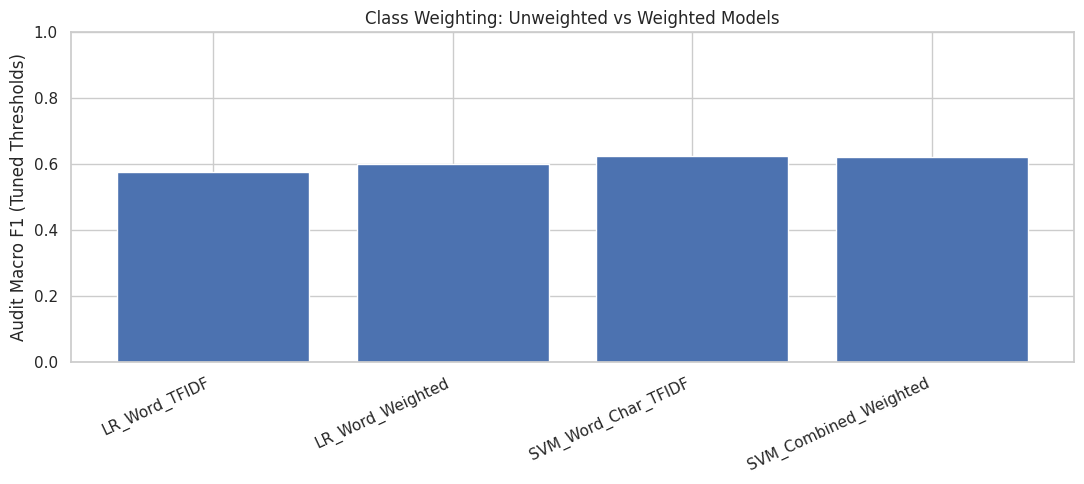


CELL 13 COMPLETED SUCCESSFULLY!


In [18]:

# ============================================================
# CELL 13: CLASS-WEIGHTED LOGISTIC REGRESSION AND LINEAR SVM
# ============================================================

import os
import json
import time
import joblib
import numpy as np
import pandas as pd

from scipy.sparse import hstack
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import (
    precision_recall_curve,
    precision_recall_fscore_support,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42
DATA_PATH = "/content/jigsaw-toxic-comment-classification-challenge.zip"
OUTPUT_DIR = "/content/jigsaw_research"

LABELS = [
    "toxic", "severe_toxic", "obscene",
    "threat", "insult", "identity_hate"
]

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============================================================
# 2. LOAD FIXED SPLITS
# ============================================================

train_split = pd.read_csv(
    f"{OUTPUT_DIR}/train_split.csv"
)

val_split = pd.read_csv(
    f"{OUTPUT_DIR}/validation_split.csv"
)

y_train = train_split[LABELS].to_numpy(dtype=int)
y_val = val_split[LABELS].to_numpy(dtype=int)

indices = np.load(
    f"{OUTPUT_DIR}/threshold_split_indices.npz"
)

tune_idx = indices["tune_idx"]
audit_idx = indices["audit_idx"]

print("Training samples:", len(y_train))
print("Validation samples:", len(y_val))
print("Threshold tuning samples:", len(tune_idx))
print("Audit samples:", len(audit_idx))

# ============================================================
# 3. LOAD EXISTING TF-IDF FEATURES
# ============================================================

word_vectorizer = joblib.load(
    f"{OUTPUT_DIR}/tfidf_word_vectorizer.joblib"
)

char_vectorizer = joblib.load(
    f"{OUTPUT_DIR}/char_tfidf_vectorizer.joblib"
)

X_train_word = word_vectorizer.transform(
    train_split["comment_text"].fillna("")
)

X_val_word = word_vectorizer.transform(
    val_split["comment_text"].fillna("")
)

X_train_char = char_vectorizer.transform(
    train_split["comment_text"].fillna("")
)

X_val_char = char_vectorizer.transform(
    val_split["comment_text"].fillna("")
)

weight = 1.0 / np.sqrt(2.0)

X_train_combined = hstack(
    [X_train_word * weight, X_train_char * weight],
    format="csr",
    dtype=np.float32
)

X_val_combined = hstack(
    [X_val_word * weight, X_val_char * weight],
    format="csr",
    dtype=np.float32
)

print("\nWord features:", X_train_word.shape)
print("Combined features:", X_train_combined.shape)

# ============================================================
# 4. DEFINE CLASS-WEIGHTED MODELS
# ============================================================

experiments = {
    "LR_Word_Weighted": {
        "model": OneVsRestClassifier(
            LogisticRegression(
                C=1.0,
                class_weight="balanced",
                max_iter=1500,
                solver="liblinear",
                random_state=SEED
            ),
            n_jobs=1
        ),
        "X_train": X_train_word,
        "X_val": X_val_word,
        "score_key": "y_prob",
        "default_threshold": 0.5,
        "baseline": "LR_Word_TFIDF"
    },

    "SVM_Combined_Weighted": {
        "model": OneVsRestClassifier(
            LinearSVC(
                C=1.0,
                class_weight="balanced",
                dual="auto",
                max_iter=5000,
                random_state=SEED
            ),
            n_jobs=1
        ),
        "X_train": X_train_combined,
        "X_val": X_val_combined,
        "score_key": "y_score",
        "default_threshold": 0.0,
        "baseline": "SVM_Word_Char_TFIDF"
    }
}

# ============================================================
# 5. THRESHOLD OPTIMIZATION FUNCTION
# ============================================================

def find_best_threshold(y_true, scores, default_threshold):

    if len(np.unique(y_true)) < 2:
        return float(default_threshold)

    precision, recall, thresholds = (
        precision_recall_curve(y_true, scores)
    )

    if len(thresholds) == 0:
        return float(default_threshold)

    p = precision[:-1]
    r = recall[:-1]

    f1_values = (
        2 * p * r / np.maximum(p + r, 1e-12)
    )

    return float(thresholds[np.argmax(f1_values)])


def evaluate_scores(scores, threshold, score_key):

    if score_key == "y_score":
        pred = (scores > threshold).astype(int)
    else:
        pred = (scores >= threshold).astype(int)

    return f1_score(
        y_val[audit_idx],
        pred[audit_idx],
        average="macro",
        zero_division=0
    )


def audit_evaluation(scores, score_key, default_threshold):

    thresholds = np.array([
        find_best_threshold(
            y_val[tune_idx, j],
            scores[tune_idx, j],
            default_threshold
        )
        for j in range(len(LABELS))
    ])

    if score_key == "y_score":
        default_pred = (scores > default_threshold).astype(int)
    else:
        default_pred = (scores >= default_threshold).astype(int)

    tuned_pred = (scores >= thresholds).astype(int)

    y_audit = y_val[audit_idx]

    return {
        "Default_Macro_F1": f1_score(
            y_audit,
            default_pred[audit_idx],
            average="macro",
            zero_division=0
        ),
        "Tuned_Macro_F1": f1_score(
            y_audit,
            tuned_pred[audit_idx],
            average="macro",
            zero_division=0
        ),
        "Tuned_Micro_F1": f1_score(
            y_audit,
            tuned_pred[audit_idx],
            average="micro",
            zero_division=0
        ),
        "Macro_AP": average_precision_score(
            y_audit, scores[audit_idx], average="macro"
        ),
        "thresholds": thresholds,
        "default_pred": default_pred,
        "tuned_pred": tuned_pred
    }

# ============================================================
# 6. TRAIN AND EVALUATE WEIGHTED MODELS
# ============================================================

comparison_rows = []

for name, config in experiments.items():

    print("\n" + "=" * 60)
    print("TRAINING:", name)

    start = time.time()

    model = config["model"]
    model.fit(config["X_train"], y_train)

    if config["score_key"] == "y_prob":
        scores = model.predict_proba(config["X_val"])
    else:
        scores = model.decision_function(config["X_val"])

    elapsed = time.time() - start

    print(f"Training and prediction time: {elapsed:.2f} sec")

    # Load previously saved unweighted baseline scores
    baseline_name = config["baseline"]

    with np.load(
        f"{OUTPUT_DIR}/{baseline_name}_validation.npz"
    ) as previous:
        baseline_scores = previous[config["score_key"]].copy()
        assert np.array_equal(previous["y_true"], y_val)

    # Evaluate both models on identical audit samples
    baseline_result = audit_evaluation(
        baseline_scores,
        config["score_key"],
        config["default_threshold"]
    )

    weighted_result = audit_evaluation(
        scores,
        config["score_key"],
        config["default_threshold"]
    )

    for version, result in [
        (baseline_name, baseline_result),
        (name, weighted_result)
    ]:
        comparison_rows.append({
            "Model": version,
            "Default_Macro_F1": result["Default_Macro_F1"],
            "Tuned_Macro_F1": result["Tuned_Macro_F1"],
            "Tuned_Micro_F1": result["Tuned_Micro_F1"],
            "Macro_AP": result["Macro_AP"]
        })

    # Per-label audit comparison
    y_audit = y_val[audit_idx]

    baseline_f1 = f1_score(
        y_audit,
        baseline_result["tuned_pred"][audit_idx],
        average=None,
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_audit,
        weighted_result["tuned_pred"][audit_idx],
        average=None,
        zero_division=0
    )

    per_class = pd.DataFrame({
        "Label": LABELS,
        "Unweighted_Tuned_F1": baseline_f1,
        "Weighted_Tuned_F1": weighted_f1,
        "Difference": weighted_f1 - baseline_f1,
        "Weighted_Threshold": weighted_result["thresholds"],
        "Audit_Support": y_audit.sum(axis=0)
    })

    print("\nPER-CLASS COMPARISON:")
    display(per_class.round(4))

    per_class.to_csv(
        f"{OUTPUT_DIR}/{name}_perclass_comparison.csv",
        index=False
    )

    # Save trained model and full validation scores
    joblib.dump(
        model,
        f"{OUTPUT_DIR}/{name}.joblib"
    )

    np.savez_compressed(
        f"{OUTPUT_DIR}/{name}_validation.npz",
        y_true=y_val,
        y_score=scores,
        thresholds=weighted_result["thresholds"],
        y_pred_default=weighted_result["default_pred"],
        y_pred_tuned=weighted_result["tuned_pred"]
    )

# ============================================================
# 7. FINAL COMPARISON
# ============================================================

comparison = pd.DataFrame(comparison_rows)

comparison["Group"] = [
    "Logistic Regression",
    "Logistic Regression",
    "Combined SVM",
    "Combined SVM"
]

print("\n========== CLASS-WEIGHT EXPERIMENT ==========")

display(
    comparison[
        [
            "Model",
            "Default_Macro_F1",
            "Tuned_Macro_F1",
            "Tuned_Micro_F1",
            "Macro_AP"
        ]
    ].round(4)
)

comparison.to_csv(
    f"{OUTPUT_DIR}/class_weight_comparison.csv",
    index=False
)

# ============================================================
# 8. VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))

plt.bar(
    comparison["Model"],
    comparison["Tuned_Macro_F1"]
)

plt.title("Class Weighting: Unweighted vs Weighted Models")
plt.ylabel("Audit Macro F1 (Tuned Thresholds)")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

print("\nCELL 13 COMPLETED SUCCESSFULLY!")


In [19]:

# CHECK NORMALIZED DUPLICATE LEAKAGE
import pandas as pd

OUTPUT_DIR = "/content/jigsaw_research"

train_split = pd.read_csv(
    f"{OUTPUT_DIR}/train_split.csv"
)

val_split = pd.read_csv(
    f"{OUTPUT_DIR}/validation_split.csv"
)

def normalize_text(series):
    return (
        series.fillna("")
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

train_norm = normalize_text(train_split["comment_text"])
val_norm = normalize_text(val_split["comment_text"])

train_texts = set(train_norm)
val_texts = set(val_norm)

overlap = train_texts.intersection(val_texts)

print("========== LEAKAGE AUDIT ==========")
print("Training samples:", len(train_split))
print("Validation samples:", len(val_split))
print("Normalized text groups in both:", len(overlap))
print("Training rows affected:", train_norm.isin(overlap).sum())
print("Validation rows affected:", val_norm.isin(overlap).sum())

if len(overlap) == 0:
    print("\nPASS: No normalized duplicate overlap found.")
else:
    print("\nWARNING: Cross-split normalized duplicates found.")
    print("Treat existing scores as exploratory until addressed.")


========== LEAKAGE AUDIT ==========
Training samples: 127656
Validation samples: 31915
Normalized text groups in both: 71
Training rows affected: 80
Validation rows affected: 77

Treat existing scores as exploratory until addressed.


In [20]:

# ============================================================
# CELL 13A: DUPLICATE LEAKAGE SENSITIVITY ANALYSIS
# NO MODEL RETRAINING REQUIRED
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    f1_score,
    average_precision_score,
    precision_recall_curve,
    precision_recall_fscore_support
)

OUTPUT_DIR = "/content/jigsaw_research"

LABELS = [
    "toxic", "severe_toxic", "obscene",
    "threat", "insult", "identity_hate"
]

# ============================================================
# 1. LOAD EXISTING DATA SPLITS
# ============================================================

train_split = pd.read_csv(
    f"{OUTPUT_DIR}/train_split.csv"
)

val_split = pd.read_csv(
    f"{OUTPUT_DIR}/validation_split.csv"
)

y_val = val_split[LABELS].to_numpy(dtype=int)

indices = np.load(
    f"{OUTPUT_DIR}/threshold_split_indices.npz"
)

tune_idx = indices["tune_idx"]
audit_idx = indices["audit_idx"]

# ============================================================
# 2. NORMALIZE TEXT
# ============================================================

def normalize_text(series):
    return (
        series.fillna("")
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

train_norm = normalize_text(
    train_split["comment_text"]
)

val_norm = normalize_text(
    val_split["comment_text"]
)

train_texts = set(train_norm)

# Keep validation examples that do not occur in training
clean_mask = (
    ~val_norm.isin(train_texts)
).to_numpy()

print("========== LEAKAGE REPORT ==========")

print("Original validation:", len(val_split))
print("Overlapping validation rows:", (~clean_mask).sum())
print("Clean validation:", clean_mask.sum())

assert clean_mask.sum() > 0

# ============================================================
# 3. CLEAN THRESHOLD-TUNING AND AUDIT SUBSETS
# ============================================================

clean_tune_idx = tune_idx[
    clean_mask[tune_idx]
]

initial_clean_audit_idx = audit_idx[
    clean_mask[audit_idx]
]

# Remove audit examples duplicating tuning examples
tune_texts = set(
    val_norm.iloc[clean_tune_idx]
)

audit_duplicates = (
    val_norm.iloc[initial_clean_audit_idx]
    .isin(tune_texts)
    .to_numpy()
)

clean_audit_idx = initial_clean_audit_idx[
    ~audit_duplicates
]

print("\nOriginal tuning samples:", len(tune_idx))
print("Clean tuning samples:", len(clean_tune_idx))

print("\nOriginal audit samples:", len(audit_idx))
print("Clean audit samples:", len(clean_audit_idx))

print(
    "Audit rows excluded due to tuning overlap:",
    audit_duplicates.sum()
)

assert len(clean_tune_idx) > 0
assert len(clean_audit_idx) > 0

assert set(
    val_norm.iloc[clean_tune_idx]
).isdisjoint(
    set(val_norm.iloc[clean_audit_idx])
)

# ============================================================
# 4. THRESHOLD OPTIMIZATION FUNCTION
# ============================================================

def best_threshold(y_true, scores, default):

    if len(np.unique(y_true)) < 2:
        return float(default)

    precision, recall, thresholds = (
        precision_recall_curve(y_true, scores)
    )

    if len(thresholds) == 0:
        return float(default)

    p = precision[:-1]
    r = recall[:-1]

    f1_values = (
        2 * p * r / np.maximum(p + r, 1e-12)
    )

    return float(
        thresholds[np.argmax(f1_values)]
    )

# ============================================================
# 5. MODEL CONFIGURATION
# ============================================================

# score_type is "prob" or "decision".
# Weighted LR uses probability scores saved under y_score.

MODELS = {
    "LR_Word_TFIDF": ("y_prob", "prob", 0.5),
    "NB_Word_TFIDF": ("y_prob", "prob", 0.5),
    "SVM_Word_TFIDF": ("y_score", "decision", 0.0),
    "DT_Word_TFIDF": ("y_prob", "prob", 0.5),
    "RF_Word_TFIDF": ("y_prob", "prob", 0.5),
    "LR_Char_TFIDF": ("y_prob", "prob", 0.5),
    "SVM_Char_TFIDF": ("y_score", "decision", 0.0),
    "SVM_Word_Char_TFIDF": ("y_score", "decision", 0.0),
    "LR_Word_Weighted": ("y_score", "prob", 0.5),
    "SVM_Combined_Weighted": ("y_score", "decision", 0.0)
}

# ============================================================
# 6. REEVALUATE SAVED PREDICTIONS
# ============================================================

results = []

for model_name, (score_key, score_type, default) in MODELS.items():

    path = (
        f"{OUTPUT_DIR}/{model_name}_validation.npz"
    )

    if not os.path.exists(path):
        raise FileNotFoundError(path)

    with np.load(path) as saved:
        scores = saved[score_key].copy()
        saved_labels = saved["y_true"].copy()

    assert np.array_equal(saved_labels, y_val), (
        f"Label alignment mismatch: {model_name}"
    )

    assert scores.shape == y_val.shape

    # Default-threshold predictions
    if score_type == "decision":
        pred_default = (scores > default).astype(int)
    else:
        pred_default = (scores >= default).astype(int)

    # Original full-validation evaluation
    original_f1 = f1_score(
        y_val,
        pred_default,
        average="macro",
        zero_division=0
    )

    # Clean full-validation evaluation
    clean_full_f1 = f1_score(
        y_val[clean_mask],
        pred_default[clean_mask],
        average="macro",
        zero_division=0
    )

    # Tune six thresholds using CLEAN tuning subset
    thresholds = np.array([
        best_threshold(
            y_val[clean_tune_idx, j],
            scores[clean_tune_idx, j],
            default
        )
        for j in range(len(LABELS))
    ])

    pred_tuned = (
        scores >= thresholds
    ).astype(int)

    # Compare on identical CLEAN audit samples
    y_audit = y_val[clean_audit_idx]

    default_audit_f1 = f1_score(
        y_audit,
        pred_default[clean_audit_idx],
        average="macro",
        zero_division=0
    )

    tuned_audit_f1 = f1_score(
        y_audit,
        pred_tuned[clean_audit_idx],
        average="macro",
        zero_division=0
    )

    macro_ap = average_precision_score(
        y_audit,
        scores[clean_audit_idx],
        average="macro"
    )

    results.append({
        "Model": model_name,
        "Original_Full_F1": original_f1,
        "Clean_Full_F1": clean_full_f1,
        "Full_F1_Difference": clean_full_f1 - original_f1,
        "Clean_Audit_Default_F1": default_audit_f1,
        "Clean_Audit_Tuned_F1": tuned_audit_f1,
        "Clean_Audit_Tuning_Gain": (
            tuned_audit_f1 - default_audit_f1
        ),
        "Clean_Audit_Macro_AP": macro_ap
    })

    # Save cleaned thresholds
    pd.DataFrame({
        "Label": LABELS,
        "Threshold": thresholds
    }).to_csv(
        f"{OUTPUT_DIR}/{model_name}_clean_thresholds.csv",
        index=False
    )

    # Save per-class details for the main SVM
    if model_name == "SVM_Word_Char_TFIDF":

        p, r, f1, support = (
            precision_recall_fscore_support(
                y_audit,
                pred_tuned[clean_audit_idx],
                average=None,
                zero_division=0
            )
        )

        per_class = pd.DataFrame({
            "Label": LABELS,
            "Precision": p,
            "Recall": r,
            "F1": f1,
            "Support": support,
            "Threshold": thresholds
        })

        print("\n========== CLEAN COMBINED SVM ==========")
        display(per_class.round(4))

# ============================================================
# 7. FINAL COMPARISON
# ============================================================

comparison = pd.DataFrame(results)

comparison = comparison.sort_values(
    "Clean_Audit_Tuned_F1",
    ascending=False
).reset_index(drop=True)

print("\n========== LEAKAGE SENSITIVITY ==========")

display(
    comparison[
        [
            "Model",
            "Original_Full_F1",
            "Clean_Full_F1",
            "Full_F1_Difference"
        ]
    ].round(4)
)

print("\n========== CLEAN AUDIT RESULTS ==========")

display(
    comparison[
        [
            "Model",
            "Clean_Audit_Default_F1",
            "Clean_Audit_Tuned_F1",
            "Clean_Audit_Tuning_Gain",
            "Clean_Audit_Macro_AP"
        ]
    ].round(4)
)

# ============================================================
# 8. SAVE CORRECTED RESULTS
# ============================================================

comparison.to_csv(
    f"{OUTPUT_DIR}/leakage_sensitivity_results.csv",
    index=False
)

np.savez_compressed(
    f"{OUTPUT_DIR}/clean_evaluation_indices.npz",
    clean_full_idx=np.flatnonzero(clean_mask),
    clean_tune_idx=clean_tune_idx,
    clean_audit_idx=clean_audit_idx
)

print("\nCELL 13A COMPLETED SUCCESSFULLY!")
print("No models were retrained.")
print("Original experiment files remain unchanged.")


========== LEAKAGE REPORT ==========
Original validation: 31915
Overlapping validation rows: 77
Clean validation: 31838

Original tuning samples: 15957
Clean tuning samples: 15911

Original audit samples: 15958
Clean audit samples: 15923
Audit rows excluded due to tuning overlap: 4

========== CLEAN COMBINED SVM ==========


,Label,Precision,Recall,F1,Support,Threshold
0,toxic,0.8365,0.7690,0.8014,1524,-0.2013
1,severe_toxic,0.4208,0.5812,0.4882,160,-0.3848
2,obscene,0.8193,0.8086,0.8139,841,-0.3147
3,threat,0.3898,0.4894,0.4340,47,-0.5332
4,insult,0.6963,0.7621,0.7277,782,-0.3152
5,identity_hate,0.4828,0.4965,0.4895,141,-0.3744



========== LEAKAGE SENSITIVITY ==========


,Model,Original_Full_F1,Clean_Full_F1,Full_F1_Difference
0,SVM_Word_Char_TFIDF,0.5839,0.5841,0.0001
1,SVM_Char_TFIDF,0.5835,0.5836,0.0001
2,SVM_Combined_Weighted,0.6296,0.6308,0.0012
3,LR_Char_TFIDF,0.4800,0.4805,0.0005
4,SVM_Word_TFIDF,0.5629,0.5628,-0.0001
5,LR_Word_Weighted,0.5733,0.5733,-0.0000
6,LR_Word_TFIDF,0.4663,0.4667,0.0004
7,RF_Word_TFIDF,0.0042,0.0041,-0.0001
8,NB_Word_TFIDF,0.2573,0.2568,-0.0005
9,DT_Word_TFIDF,0.3406,0.3405,-0.0001



========== CLEAN AUDIT RESULTS ==========


,Model,Clean_Audit_Default_F1,Clean_Audit_Tuned_F1,Clean_Audit_Tuning_Gain,Clean_Audit_Macro_AP
0,SVM_Word_Char_TFIDF,0.5675,0.6258,0.0582,0.6433
1,SVM_Char_TFIDF,0.5751,0.6226,0.0476,0.6381
2,SVM_Combined_Weighted,0.6105,0.6224,0.0120,0.6369
3,LR_Char_TFIDF,0.4665,0.6103,0.1438,0.6357
4,SVM_Word_TFIDF,0.5472,0.6088,0.0616,0.6150
5,LR_Word_Weighted,0.5679,0.5994,0.0315,0.6177
6,LR_Word_TFIDF,0.4538,0.5779,0.1242,0.6079
7,RF_Word_TFIDF,0.0032,0.5502,0.5470,0.5592
8,NB_Word_TFIDF,0.2602,0.4561,0.1959,0.4482
9,DT_Word_TFIDF,0.3072,0.3831,0.0759,0.2886



CELL 13A COMPLETED SUCCESSFULLY!
No models were retrained.
Original experiment files remain unchanged.
